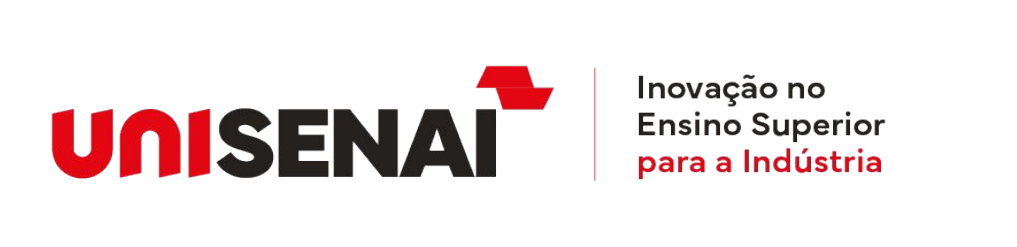

**PÓS-GRADUAÇÃO**  
Data Science & Big Data Aplicados na Indústria

---

# Aula 03 — Machine Learning e tratamento de dados na indústria

**Matéria: Data Science e Big Data**

| Identificação | Informações |
| :--- | :--- |
| **Aluno** | Carlos Pereira |
| **Disciplina** | Data Science e Big Data |
| **Professor** | Daniel Vieira |

> **Todos os exemplos do PDF — páginas 10 a 66.**  
> Árvore de Decisão, Random Forest, avaliação e comparação de modelos, tratamento de dados e classificação do consumo energético. Contextualização teórica baseada nas páginas 2 a 9.

---


# Aula 03 completa: Machine Learning e tratamento de dados na indústria
## Todos os exemplos do PDF em uma aula guiada

**Da pergunta industrial à avaliação:** Árvore de Decisão, Random Forest e classificação do consumo energético com preparação de dados.

Este caderno preserva a primeira aula guiada e completa as implementações do PDF de 68 páginas. Execute as células em ordem usando Python 3. As saídas já estão salvas para leitura.

| Parte | Conteúdo | Páginas |
|---|---|---|
| Fundamentos e exemplo 1A | Contexto, 20 máquinas, árvore, interpretação e métricas | 2–28 |
| Exemplo 1B | Random Forest, comparação, nova máquina e árvores da floresta | 29–39 |
| Exemplo 2 | CSV, exploração, limpeza, distribuições, pipelines e comparação | 40–64 |
| Síntese | Custos dos erros e programação versus aprendizado | 65–66 |

As páginas 1, 67 e 68 apresentam capa, material de apoio e encerramento. Mantenha o CSV original `consumo_energetico_alunos.csv` junto deste notebook. Depois de instalar as bibliotecas, a execução não exige internet.

**Como estudar:** acompanhe o fluxo; explique cada saída com suas palavras; depois altere os experimentos. Os complementos autorais são identificados e as correções em relação aos slides são explicadas.

## 1. Antes do código: o problema que queremos resolver

Na página 9, uma indústria deseja identificar máquinas que operam de maneira eficiente. O material fornece 20 registros com produção, energia e uma classificação já conhecida. Nosso modelo aprenderá a reproduzir esses rótulos.

Isso é **aprendizado supervisionado**, pois temos exemplos com respostas (página 5), e **classificação binária**, pois a resposta assume duas classes. Agrupar máquinas sem rótulos seria outro problema, de aprendizado não supervisionado (página 6).

| Campo | Papel no modelo | Significado no exemplo |
|---|---|---|
| `producao` | Entrada em `X` | Quantidade de peças produzidas |
| `energia` | Entrada em `X` | Consumo em kWh |
| `eficiente` | Resposta em `y` | 0 = Ineficiente; 1 = Eficiente |

**O que sabemos e o que falta:** o PDF fornece os rótulos, mas não define o período de medição, o critério técnico que os gerou nem a origem dos registros. Trataremos a base como material didático; sua representatividade industrial não foi demonstrada. Comparações entre máquinas reais exigiriam condições e períodos compatíveis.

### Como este exemplo percorre um projeto de Data Science

A sequência da página 2 vira um roteiro prático:

| Etapa do projeto | O que faremos aqui | Evidência observável |
|---|---|---|
| Definição do problema | Prever o rótulo de eficiência | Entradas e resposta definidas |
| Preparação | Montar e conferir os 20 registros | Tabela, tipos, ausências e classes |
| Escolha do algoritmo | Usar uma árvore de decisão | Regra que pode ser inspecionada |
| Teste | Reservar quatro registros antes do ajuste | Comparação entre resposta e previsão |
| Visualização e interpretação | Ler a árvore e discutir seus limites | Gráficos, métricas e experimentos |

A página 4 apresenta **dados → algoritmo → modelo → previsão**. Em código: `X_treino, y_treino` → `fit()` → `modelo_arvore` → `predict(X_teste)`.

O teste deve permanecer fora do treinamento. Usá-lo repetidamente para escolher ajustes também reduz sua independência como avaliação final.

### Uma história para acompanhar o exemplo

Imagine que você recebeu a tabela da equipe de operações e precisa explicar uma previsão para uma pessoa que conhece as máquinas, mas não conhece Python. Seu trabalho terá três perguntas diferentes:

1. **O que aconteceu?** A tabela mostra produção, energia e rótulos conhecidos.
2. **Que padrão o algoritmo aprendeu?** A árvore descreve uma regra a partir do treino.
3. **Quanto podemos confiar?** A comparação no teste oferece uma evidência limitada sobre registros que não participaram do ajuste.

Não confunda essas perguntas. Uma regra fácil de explicar pode ter avaliação frágil; uma previsão correta pode ocorrer em uma base pouco representativa.

### Por que uma árvore de decisão?

Uma árvore faz perguntas sucessivas, como “a produção é menor ou igual a um limite?”. Cada resposta direciona para um ramo. Isso permite transformar o modelo em um desenho e em regras legíveis.

No treinamento, o algoritmo procura divisões que reduzam a mistura das classes. Ele testa possibilidades a partir dos dados; nós não programamos antecipadamente o corte de 775 peças. Fixamos o algoritmo e os parâmetros; o limite é aprendido.

**Vocabulário que será usado:** observação = uma linha; atributo ou característica = uma entrada; rótulo ou alvo = resposta conhecida; treino = dados usados no ajuste; teste = dados reservados para avaliar; inferência = aplicar o modelo a entradas.

### Planeje sua leitura

| Passagem | Seu objetivo | Quando avançar |
|---|---|---|
| Primeira | Executar e acompanhar o fluxo | Quando souber de onde vem cada variável |
| Segunda | Explicar cada resultado com suas palavras | Quando conseguir ler a árvore e a matriz |
| Terceira | Alterar os experimentos | Quando conseguir prever o efeito antes de executar |

Você não precisa decorar todos os imports. Concentre-se no caminho dos dados e no papel de cada comando.

## 2. Preparação do ambiente · página 10
A célula opcional instala as bibliotecas no kernel atual. Os imports seguintes preservam os do slide. Random Forest será treinado na parte 1B.

In [1]:
# Execute somente se alguma biblioteca estiver ausente:
# %pip install pandas matplotlib scikit-learn

In [2]:
#1. Importação das bibliotecas
# Biblioteca para manipulação de dados
import pandas as pd
# Biblioteca para criação de gráficos
import matplotlib.pyplot as plt

# Algoritmo de Árvore de Decisão e sua visualização
from sklearn.tree import DecisionTreeClassifier, plot_tree

# Algoritmo Random Forest
from sklearn.ensemble import RandomForestClassifier

# Função para dividir os dados em treinamento e teste
from sklearn.model_selection import train_test_split

# Funções para avaliar os modelos de classificação
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)


In [3]:
from IPython.display import display
from sklearn.tree import export_text
plt.rcParams.update({"figure.dpi": 110, "font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
ROTULOS = {0: "Ineficiente", 1: "Eficiente"}
CORES = {0: "#c56a22", 1: "#147d92"}

### Como ler os comandos que aparecem a seguir

| Sintaxe | Como ler | Exemplo |
|---|---|---|
| `import ... as ...` | Carregar uma biblioteca com um apelido | `pd` representa `pandas` |
| `from ... import ...` | Importar um recurso específico | `DecisionTreeClassifier` |
| `nome = valor` | Guardar um objeto em uma variável | `df = pd.DataFrame(dados)` |
| `objeto.metodo(...)` | Pedir uma operação a um objeto | `modelo_arvore.fit(...)` |
| `# comentário` | Explicação que o Python não executa | `# Consumo em kWh` |
| `[...]` | Lista ou seleção, conforme o contexto | `[1000, 500]` ou `df["energia"]` |
| `{...}` | Dicionário com pares chave e valor | `{"energia": [200, 250]}` |

**Biblioteca, algoritmo e modelo são coisas diferentes:** scikit-learn é a biblioteca; árvore de decisão é a família de algoritmo; `modelo_arvore` é o objeto que, após `fit()`, contém as divisões aprendidas nesta base.

Se aparecer `ModuleNotFoundError`, habilite a instalação no kernel que está executando o notebook. Se aparecer `NameError`, normalmente uma célula anterior não foi executada. Para conferir a sequência, reinicie o kernel e execute todas as células em ordem.

## 3. Construção da base · página 11
Os valores abaixo são os mesmos do PDF. Cada linha corresponde a um registro do exemplo; o índice apenas identifica a linha e não será usado como preditor.

In [4]:
#2. Criação do conjunto de dados
# Criando um conjunto de dados de 20 máquinas industriais
dados = {
    # Quantidade de peças produzidas
    "producao": [
        1000, 500, 1200, 400, 1100,
        300, 950, 450, 1050, 550,
        1300, 600, 1150, 350, 900,
        650, 1250, 480, 1080, 520],
    # Consumo de energia em kWh
    "energia": [
        200, 250, 240, 300, 220,
        280, 210, 270, 230, 310,
        260, 290, 235, 260, 195,
        320, 250, 295, 225, 275
    ],
    # Classificação conhecida de cada máquina
    # 1 = Eficiente
    # 0 = Ineficiente
    "eficiente": [
        1, 0, 1, 0, 1,
        0, 1, 0, 1, 0,
        1, 0, 1, 0, 1,
        0, 1, 0, 1, 0
    ]
}
# Transforma o dicionário em um DataFrame
df = pd.DataFrame(dados)
print(df)#Exibe os dados


    producao  energia  eficiente
0       1000      200          1
1        500      250          0
2       1200      240          1
3        400      300          0
4       1100      220          1
5        300      280          0
6        950      210          1
7        450      270          0
8       1050      230          1
9        550      310          0
10      1300      260          1
11       600      290          0
12      1150      235          1
13       350      260          0
14       900      195          1
15       650      320          0
16      1250      250          1
17       480      295          0
18      1080      225          1
19       520      275          0


### Entenda como a tabela é construída

`dados` é um dicionário: cada chave será o nome de uma coluna e cada lista fornecerá seus valores. A posição conecta os campos: o primeiro valor de produção, o primeiro de energia e o primeiro rótulo pertencem ao mesmo registro.

`pd.DataFrame(dados)` transforma essa estrutura em uma tabela. `print(df)` mostra as linhas sem treinar nenhum modelo. O número à esquerda é o índice, começando em zero; ele não é a produção nem o identificador técnico de uma máquina.

**Exemplo de leitura:** a linha 0 tem 1.000 peças, 200 kWh e rótulo 1. A linha 1 tem 500 peças, 250 kWh e rótulo 0. O rótulo foi fornecido; o código não o calcula dividindo produção por energia.

Antes de continuar, tente responder: quantos valores deve haver em cada lista? **Vinte**, pois cada coluna descreve os mesmos vinte registros. Listas de comprimentos diferentes não formam este DataFrame.

### Complemento: conferir antes de treinar
Verificamos a estrutura sem modificar os dados. Ter colunas numéricas e nenhum valor ausente permite seguir diretamente neste exemplo; isso não garante que os registros representem toda a operação industrial.

In [5]:
assert df.shape == (20, 3)
assert not df.isna().any().any()
assert set(df["eficiente"].unique()) == {0, 1}
display(pd.DataFrame({"tipo": df.dtypes.astype(str), "ausentes": df.isna().sum()}))
display(df.groupby("eficiente").agg(
    registros=("producao", "size"),
    producao_min=("producao", "min"), producao_max=("producao", "max"),
    energia_min=("energia", "min"), energia_max=("energia", "max")
).rename(index=ROTULOS))

,tipo,ausentes
producao,int64,0
energia,int64,0
eficiente,int64,0


,registros,producao_min,producao_max,energia_min,energia_max
eficiente,,,,,
Ineficiente,10,300,650,250,320
Eficiente,10,900,1300,195,260


### Complemento: enxergar o padrão dos dados
Cada ponto é uma máquina. A cor mostra a resposta conhecida. Observe se as classes se separam pela produção, pela energia ou por ambas. Este gráfico explora a base didática completa; não será usado para escolher ajustes do modelo.

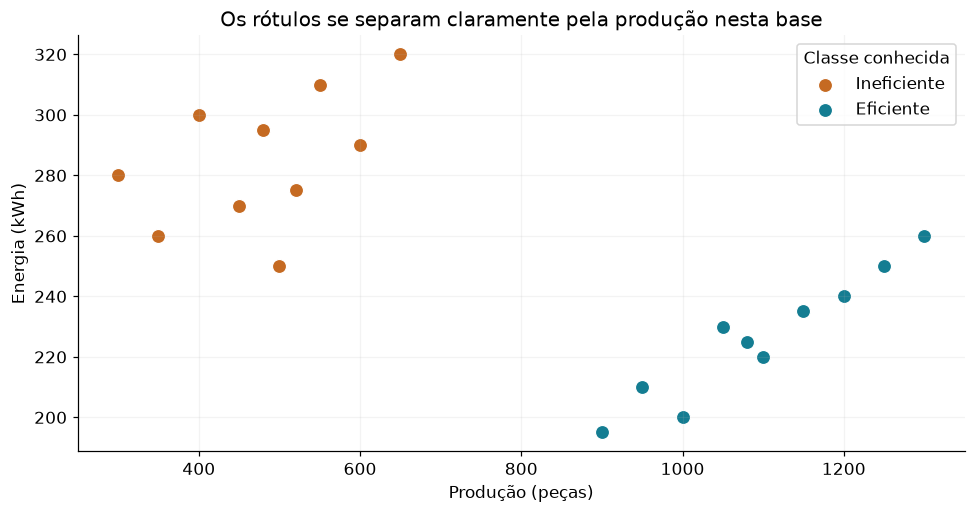

In [6]:
fig, ax = plt.subplots(figsize=(9, 4.8))
for classe, grupo in df.groupby("eficiente"):
    ax.scatter(grupo["producao"], grupo["energia"], s=85, color=CORES[classe],
               label=ROTULOS[classe], edgecolors="white", linewidth=0.8)
ax.set(xlabel="Produção (peças)", ylabel="Energia (kWh)", title="Os rótulos se separam claramente pela produção nesta base")
ax.legend(title="Classe conhecida")
ax.grid(alpha=0.15)
plt.tight_layout()
plt.show()

### O que o gráfico permite observar?

Nesta tabela, os registros rotulados como ineficientes têm produção de 300 a 650 peças; os eficientes, de 900 a 1.300. Já as faixas de energia têm sobreposição. Isso ajuda a entender por que uma única divisão por produção poderá separar as classes.

**Correlação observada não é explicação causal.** A base associa produção elevada ao rótulo eficiente, mas não demonstra que elevar a produção cause eficiência. Também não informa se as máquinas têm capacidades, produtos ou turnos comparáveis.

**Pergunta para pensar:** uma máquina com alta produção e enorme consumo necessariamente seria eficiente? A definição técnica precisaria considerar o processo; o nosso modelo responderá conforme o padrão dos rótulos disponíveis.

## 4. Entradas, resposta e separação dos dados · páginas 12 e 13
`X` recebe produção e energia. `y` recebe o rótulo. Incluir `eficiente` em `X` revelaria a própria resposta ao modelo, causando vazamento de informação.

In [7]:
#3. Separação das variáveis X e y
# X representa as características utilizadas pelo modelo
# São chamadas de variáveis independentes ou preditoras
X = df[["producao", "energia"]]

# y representa a classificação que queremos prever
# É chamada de variável-alvo
y = df["eficiente"]


Reservamos **80% para treino** e **20% para teste**. `random_state=42` fixa o sorteio para reproduzir a execução; não melhora a qualidade dos dados. `stratify=y` mantém, nesta base balanceada, a proporção de classes em ambos os conjuntos. Aqui há um conjunto de teste, sem um conjunto separado de validação.

In [8]:
#4. Divisão em treinamento e teste
# Divide o conjunto de dados em treinamento e teste
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X,                      # Variáveis de entrada
    y,                      # Classificações conhecidas
    test_size=0.20,         # Reserva 20% dos dados para teste
    random_state=42,        # Mantém o mesmo sorteio em cada execução
    stratify=y              # Preserva a proporção das classes
)

# Exibe a quantidade de registros de cada conjunto
print("Treinamento:", len(X_treino))
print("Teste:", len(X_teste))


Treinamento: 16
Teste: 4


In [9]:
assert set(X_treino.index).isdisjoint(X_teste.index)
display(pd.DataFrame({
    "Treino": y_treino.value_counts(), "Teste": y_teste.value_counts()
}).rename(index=ROTULOS))

,Treino,Teste
eficiente,,
Ineficiente,8,2
Eficiente,8,2


### Desmontando `X`, `y` e a separação

`df[["producao", "energia"]]` usa uma lista de nomes para selecionar duas colunas e produzir um DataFrame. `df["eficiente"]` seleciona uma coluna e produz uma Series. A diferença importa porque o modelo recebe várias entradas e uma resposta por registro.

A atribuição com quatro nomes recebe os quatro resultados de `train_test_split` na mesma ordem: entradas de treino, entradas de teste, respostas de treino e respostas de teste. A função mantém cada entrada alinhada com seu rótulo.

**Conta do tamanho:** 20 × 0,20 = 4 registros de teste; os outros 16 vão para treino. Como há 10 registros de cada classe, a separação estratificada fica com 8 de cada classe no treino e 2 de cada classe no teste.

**Por que o índice pode parecer fora de ordem?** O sorteio mistura registros, preservando os índices originais. Isso é esperado. Não ordene ou embaralhe `y` separadamente de `X`: você poderia associar uma máquina à resposta de outra.

### Três vazamentos de informação para reconhecer

| Situação | Por que prejudica a avaliação | Procedimento adequado |
|---|---|---|
| Colocar `eficiente` em `X` | O modelo recebe a própria resposta | Selecionar somente preditores disponíveis na previsão |
| Treinar com a base inteira antes de medir no teste | Os casos avaliados já influenciaram o modelo | Separar primeiro e ajustar com o treino |
| Escolher muitos ajustes pelo melhor resultado no teste | O teste influencia a escolha final | Usar validação no treino e preservar um teste final |

Este exemplo não precisa de normalização para a árvore. Em projetos com transformações aprendidas dos dados, essas transformações também devem ser ajustadas apenas no treino.

In [10]:
# Formatos esperados: 20 linhas e 2 entradas; 20 respostas.
print("X completo:", X.shape, "| y completo:", y.shape)
print("Entradas de treino:", X_treino.shape)
print("Entradas de teste:", X_teste.shape)
print("As entradas e respostas de treino estão alinhadas?", X_treino.index.equals(y_treino.index))
print("Há índices compartilhados entre treino e teste?", bool(set(X_treino.index) & set(X_teste.index)))

X completo: (20, 2) | y completo: (20,)
Entradas de treino: (16, 2)
Entradas de teste: (4, 2)
As entradas e respostas de treino estão alinhadas? True
Há índices compartilhados entre treino e teste? False


## 5. Aprender com o treino, prever no teste · página 14
`DecisionTreeClassifier(...)` configura o algoritmo. `fit()` aprende divisões usando apenas o treino. `predict()` aplica as divisões aos registros de teste, sem receber suas respostas.

In [11]:
#5. Treinamento da Árvore de Decisão
# Cria o algoritmo de classificação
modelo_arvore = DecisionTreeClassifier(
    random_state=42
)

# Treina a árvore utilizando somente os dados de treinamento
modelo_arvore.fit(X_treino, y_treino)

# Utiliza a árvore treinada para classificar os dados de teste
previsao_arvore = modelo_arvore.predict(X_teste)

# Exibe as classificações reais e as previstas
print("Valores reais:", y_teste.values)
print("Previsões:    ", previsao_arvore)


Valores reais: [0 0 1 1]
Previsões:     [0 0 1 1]


### O que acontece em cada linha do treinamento?

1. `DecisionTreeClassifier(random_state=42)` cria um objeto ainda sem divisões aprendidas.
2. `fit(X_treino, y_treino)` encontra divisões que associam as entradas aos rótulos de treino e guarda a árvore nesse objeto.
3. `predict(X_teste)` percorre essa árvore para cada registro reservado e retorna os códigos das classes.
4. A comparação com `y_teste` verifica o resultado. Essas respostas não foram passadas a `predict()`.

**Não há aprendizagem contínua nesta sequência:** executar `predict()` não atualiza a árvore. Se você modificar `df` depois do treinamento, o modelo já ajustado não muda automaticamente; é necessário reconstruir as entradas e refazer o ajuste para treinar sobre os novos dados.

**Algoritmo versus resultado:** uma árvore pode aprender múltiplas divisões. O fato de esta árvore precisar apenas de uma divisão é uma característica deste conjunto, não uma limitação geral do algoritmo.

### Complemento: conferir cada previsão
A comparação por registro é mais informativa que olhar apenas dois vetores. A coluna `acertou` compara a previsão com o rótulo fornecido no material.

In [12]:
comparacao = X_teste.copy()
comparacao["classe_real"] = y_teste.map(ROTULOS)
comparacao["classe_prevista"] = pd.Series(previsao_arvore, index=X_teste.index).map(ROTULOS)
comparacao["acertou"] = y_teste.to_numpy() == previsao_arvore
display(comparacao)

,producao,energia,classe_real,classe_prevista,acertou
13,350,260,Ineficiente,Ineficiente,True
7,450,270,Ineficiente,Ineficiente,True
4,1100,220,Eficiente,Eficiente,True
12,1150,235,Eficiente,Eficiente,True


## 6. Visualizar a árvore · página 15
Comece pelo nó superior. Se a condição for verdadeira, siga para a esquerda; se for falsa, para a direita. Repita até chegar a uma folha, que apresenta a classe prevista.

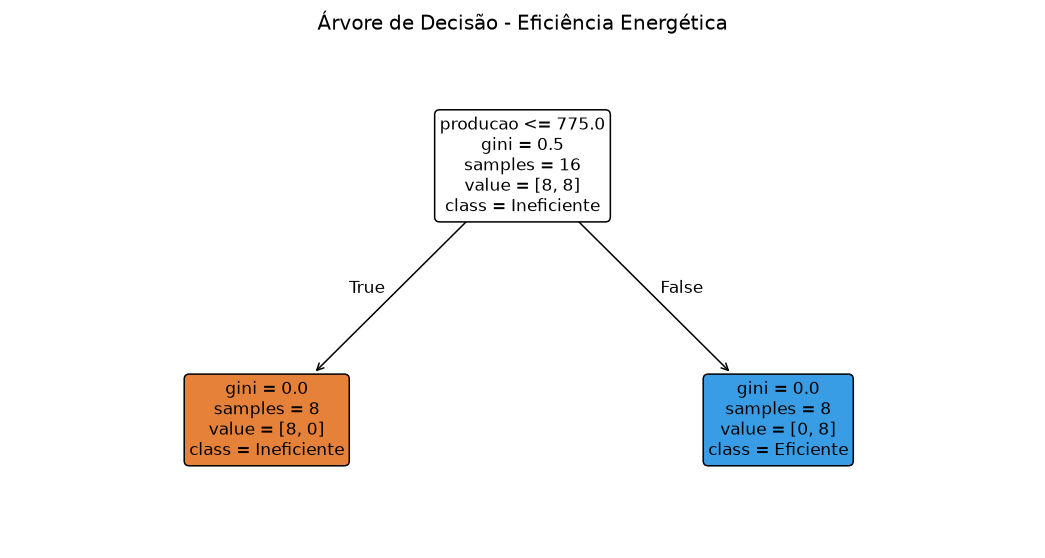

In [13]:
#6. Visualização da Árvore de Decisão
# Define o tamanho da figura
plt.figure(figsize=(12, 6))

# Desenha a árvore treinada
plot_tree(
    modelo_arvore,
    
    # Nomes das variáveis de entrada
    feature_names=["producao", "energia"],
    
    # Nomes das classes de saída (0 e 1)
    class_names=["Ineficiente", "Eficiente"],
    
    # Preenche os nós com cores de acordo com as classes
    filled=True,
    
    # Deixa as caixas com bordas arredondadas
    rounded=True,
    
    # Define o tamanho das letras
    fontsize=11
)

# Adiciona um título
plt.title("Árvore de Decisão - Eficiência Energética")

# Exibe o gráfico
plt.show()


### Complemento: traduzir o desenho em uma regra

- **`gini`** mede a mistura de classes: 0 indica um nó puro; em classificação binária, 0,5 é o máximo.
- **`samples`** conta os registros de treinamento no nó.
- **`value`** indica a distribuição das classes no nó; a apresentação pode variar conforme a versão do scikit-learn.
- **`class`** é a classe majoritária usada na previsão.

A próxima célula extrai a regra diretamente do modelo, evitando escrever um limite que poderia ficar desatualizado se você alterar os dados.

In [14]:
print(export_text(modelo_arvore, feature_names=list(X.columns)))
raiz = modelo_arvore.tree_
variavel_raiz = X.columns[raiz.feature[0]]
limiar = raiz.threshold[0]
print(f"Primeira decisão: {variavel_raiz} <= {limiar:g}")
print(f"Profundidade: {modelo_arvore.get_depth()} | Folhas: {modelo_arvore.get_n_leaves()}")
display(pd.DataFrame({"variavel": X.columns,
                      "importancia_na_arvore": modelo_arvore.feature_importances_}))

|--- producao <= 775.00
|   |--- class: 0
|--- producao >  775.00
|   |--- class: 1

Primeira decisão: producao <= 775
Profundidade: 1 | Folhas: 2


,variavel,importancia_na_arvore
0,producao,1.0
1,energia,0.0


**Leitura desta execução:** a árvore usa `producao <= 775` para separar as classes e chega a duas folhas puras, com oito registros de treino em cada uma. A energia tem importância zero nesta árvore porque a produção já separa os rótulos do treino.

Isso descreve o padrão aprendido nesta base. Não demonstra que energia seja irrelevante para eficiência industrial, nem que produzir acima de 775 peças torne uma máquina eficiente por uma lei física. O modelo reproduz os rótulos recebidos.

### Gini calculado à mão: de onde vêm 0,5 e 0?

Para um nó com duas classes, o cálculo é:

**Gini = 1 − (proporção da classe 0)² − (proporção da classe 1)².**

No início do treino há 8 registros de cada classe. Portanto:

`Gini da raiz = 1 − (8/16)² − (8/16)² = 0,5`.

Depois do corte, uma folha tem apenas classe 0 e a outra apenas classe 1. Em cada folha:

`Gini = 1 − 1² − 0² = 0`.

A impureza após uma divisão é a média dos Ginis dos filhos ponderada pelas quantidades de registros. Neste caso, `(8/16 × 0) + (8/16 × 0) = 0`. A redução é `0,5 − 0 = 0,5`.

O código seguinte reproduz essa conta com as contagens do treino. Ele explica a primeira divisão; não implementa todo o algoritmo do scikit-learn.

In [15]:
def gini_dos_rotulos(rotulos):
    # Calcula a impureza usando a proporção de cada classe presente.
    proporcoes = pd.Series(rotulos).value_counts(normalize=True)
    return float(1 - (proporcoes ** 2).sum())

vai_esquerda = X_treino[variavel_raiz] <= limiar
rotulos_esquerda = y_treino.loc[vai_esquerda]
rotulos_direita = y_treino.loc[~vai_esquerda]
gini_antes = gini_dos_rotulos(y_treino)
gini_depois = (
    len(rotulos_esquerda) / len(y_treino) * gini_dos_rotulos(rotulos_esquerda)
    + len(rotulos_direita) / len(y_treino) * gini_dos_rotulos(rotulos_direita)
)
print(f"Gini antes: {gini_antes:.2f}")
print(f"Gini depois: {gini_depois:.2f}")
print(f"Redução de impureza: {gini_antes - gini_depois:.2f}")
print("Classes à esquerda:", rotulos_esquerda.value_counts().to_dict())
print("Classes à direita:", rotulos_direita.value_counts().to_dict())

Gini antes: 0.50
Gini depois: 0.00
Redução de impureza: 0.50
Classes à esquerda: {0: 8}
Classes à direita: {1: 8}


### Por que o limite aprendido é 775 e não 650 ou 900?

No treino desta execução, 650 é a maior produção da classe 0 e 900 é a menor da classe 1. O ponto médio é `(650 + 900) / 2 = 775`. A divisão separa os registros observados sem precisar colocar o limite exatamente sobre uma observação.

Há um intervalo sem dados entre esses grupos. O algoritmo escolhe um corte, mas a base não revela a verdadeira classificação industrial de todas as produções nesse intervalo. A previsão para 776 peças continua sendo uma aplicação da regra, não uma observação confirmada.

In [16]:
maior_producao_classe_0 = X_treino.loc[y_treino == 0, "producao"].max()
menor_producao_classe_1 = X_treino.loc[y_treino == 1, "producao"].min()
print("Maior produção da classe 0 no treino:", maior_producao_classe_0)
print("Menor produção da classe 1 no treino:", menor_producao_classe_1)
print("Ponto médio:", (maior_producao_classe_0 + menor_producao_classe_1) / 2)

Maior produção da classe 0 no treino: 650
Menor produção da classe 1 no treino: 900
Ponto médio: 775.0


## 7. Avaliação da árvore · páginas 21–28 e complementos

A avaliação desenvolve as páginas 21–28. As contas manuais, a referência simples e os experimentos são complementos autorais.

Na matriz, as **linhas mostram a classe real** e as **colunas, a prevista**. Considerando `1 = Eficiente` como classe positiva:

| Medida | Pergunta respondida |
|---|---|
| Acurácia | Qual fração de todos os registros foi classificada corretamente? |
| Precisão | Entre os previstos como eficientes, quantos eram eficientes? |
| Recall | Entre os eficientes reais, quantos foram reconhecidos? |
| F1 | Como precisão e recall se combinam pela média harmônica? |

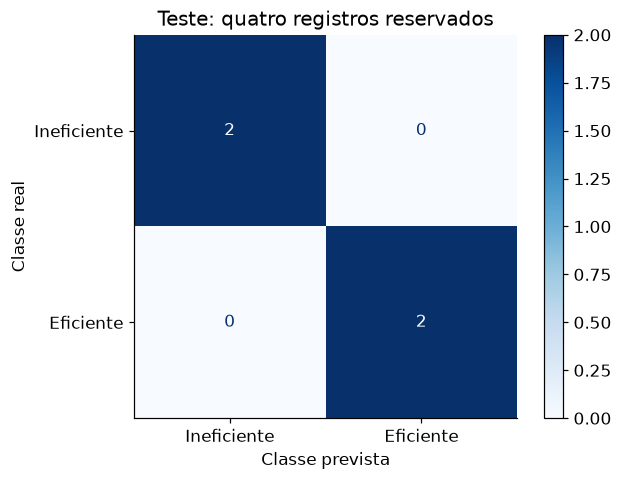

,Resultado
Acurácia,100%
Precisão (classe 1),100%
Recall (classe 1),100%
F1 (classe 1),100%


Acertos: 4 de 4
Uma única classificação errada altera a acurácia em 25 pontos percentuais.


In [17]:
fig, ax = plt.subplots(figsize=(6, 4.5))
ConfusionMatrixDisplay.from_predictions(
    y_teste, previsao_arvore, labels=[0, 1],
    display_labels=["Ineficiente", "Eficiente"], cmap="Blues",
    values_format="d", colorbar=True, ax=ax
)
ax.set(title="Teste: quatro registros reservados", xlabel="Classe prevista", ylabel="Classe real")
plt.tight_layout()
plt.show()
metricas = pd.Series({
    "Acurácia": accuracy_score(y_teste, previsao_arvore),
    "Precisão (classe 1)": precision_score(y_teste, previsao_arvore, zero_division=0),
    "Recall (classe 1)": recall_score(y_teste, previsao_arvore, zero_division=0),
    "F1 (classe 1)": f1_score(y_teste, previsao_arvore, zero_division=0)
}, name="Resultado")
display(metricas.map(lambda valor: f"{valor:.0%}").to_frame())
print(f"Acertos: {(y_teste.to_numpy() == previsao_arvore).sum()} de {len(y_teste)}")
print(f"Uma única classificação errada altera a acurácia em {100 / len(y_teste):.0f} pontos percentuais.")

**Como interpretar os 100%:** o modelo acertou os quatro registros separados neste sorteio. O teste é pequeno e os rótulos da base têm separação simples. Esse resultado não estima com segurança o desempenho em máquinas reais.

Um falso positivo seria chamar uma máquina ineficiente de eficiente; um falso negativo seria classificar uma eficiente como ineficiente. O custo de cada erro depende da decisão operacional. Antes de uma aplicação real, seria necessário definir o critério de eficiência com especialistas, coletar dados representativos e avaliar em dados independentes, respeitando tempo e identidade das máquinas.

### Métricas por dentro: a conta da matriz

Com a ordem `[0, 1]`, a matriz segue `[[TN, FP], [FN, TP]]`, considerando eficiente como classe positiva:

- **TN:** ineficiente real e previsto como ineficiente.
- **FP:** ineficiente real, mas previsto como eficiente.
- **FN:** eficiente real, mas previsto como ineficiente.
- **TP:** eficiente real e previsto como eficiente.

As fórmulas são `acurácia = (TP + TN) / total`, `precisão = TP / (TP + FP)`, `recall = TP / (TP + FN)` e `F1 = 2 × precisão × recall / (precisão + recall)`. Nesta execução há 2 TN, 2 TP e nenhum erro.

O uso de `zero_division=0` define o valor retornado quando uma métrica teria denominador zero; não melhora o modelo e não transforma ausência de evidência em sucesso.

In [18]:
tn, fp, fn, tp = confusion_matrix(y_teste, previsao_arvore, labels=[0, 1]).ravel()
print(f"TN={tn} | FP={fp} | FN={fn} | TP={tp}")
print(f"Acurácia calculada diretamente: ({tp} + {tn}) / {len(y_teste)} = {(tp + tn) / len(y_teste):.0%}")

TN=2 | FP=0 | FN=0 | TP=2
Acurácia calculada diretamente: (2 + 2) / 4 = 100%


### Comparar com uma previsão simples

Antes de celebrar um resultado, pergunte: quanto acertaria uma estratégia que ignora as entradas e sempre escolhe uma classe predominante do treino?

Essa referência é chamada de **baseline**. Ela ajuda a avaliar se o modelo acrescenta algo em relação a uma regra trivial. Em empate entre as classes, o classificador abaixo escolhe uma delas de modo determinístico. Ele é ajustado no mesmo treino e avaliado no mesmo teste.

In [19]:
from sklearn.dummy import DummyClassifier
referencia = DummyClassifier(strategy="most_frequent")
referencia.fit(X_treino, y_treino)
previsao_referencia = referencia.predict(X_teste)
display(pd.DataFrame({
    "modelo": ["Classe predominante do treino", "Árvore de decisão"],
    "acertos": [(previsao_referencia == y_teste.to_numpy()).sum(),
                (previsao_arvore == y_teste.to_numpy()).sum()],
    "total_teste": [len(y_teste), len(y_teste)],
    "acuracia": [accuracy_score(y_teste, previsao_referencia),
                 accuracy_score(y_teste, previsao_arvore)]
}))

,modelo,acertos,total_teste,acuracia
0,Classe predominante do treino,2,4,0.5
1,Árvore de decisão,4,4,1.0


A referência acerta 2 de 4 casos (50%) e a árvore acerta 4 de 4 (100%). A árvore aproveita um padrão das entradas que a referência ignora. A diferença continua sendo uma observação sobre este teste pequeno.

### Experimento mental: e se houvesse apenas um erro?

O cenário seguinte é **artificial**: trocamos uma previsão para observar o efeito na avaliação. O modelo treinado e suas previsões originais permanecem os mesmos.

In [20]:
previsao_com_um_erro = previsao_arvore.copy()
previsao_com_um_erro[0] = 1 - previsao_com_um_erro[0]
print("Acurácia original:", f"{accuracy_score(y_teste, previsao_arvore):.0%}")
print("Acurácia no cenário artificial:", f"{accuracy_score(y_teste, previsao_com_um_erro):.0%}")
print("Matriz do cenário artificial:")
print(confusion_matrix(y_teste, previsao_com_um_erro, labels=[0, 1]))

Acurácia original: 100%
Acurácia no cenário artificial: 75%
Matriz do cenário artificial:
[[1 1]
 [0 2]]


## 8. Laboratório: faça uma previsão e investigue o comportamento

**Antes de executar:** qual será a previsão para 700 e para 1.000 peças? Alterar somente a energia deverá mudar a resposta?

Os registros abaixo são **cenários inventados para exploração**, não novas observações com resposta conhecida. Você pode editar os números e executar esta célula novamente. A previsão é uma aplicação da regra aprendida, sem garantia de acerto nesses cenários.

In [21]:
novas_maquinas = pd.DataFrame({
    "producao": [700, 1000, 1000],
    "energia": [240, 200, 320]
}, index=["A", "B", "C"])
resultado_novo = novas_maquinas.copy()
resultado_novo["previsao"] = pd.Series(
    modelo_arvore.predict(novas_maquinas), index=novas_maquinas.index
).map(ROTULOS)
resultado_novo["fora_da_faixa_observada"] = (
    novas_maquinas.lt(X.min()) | novas_maquinas.gt(X.max())
).any(axis=1)
display(resultado_novo)
print("Estar dentro das faixas observadas também não garante que a previsão esteja correta.")

,producao,energia,previsao,fora_da_faixa_observada
A,700,240,Ineficiente,False
B,1000,200,Eficiente,False
C,1000,320,Eficiente,False


Estar dentro das faixas observadas também não garante que a previsão esteja correta.


### Experimento: atravessar a fronteira de decisão

Mantemos energia fixa e variamos produção em torno do limite extraído da árvore. A mudança abrupta é consequência de uma divisão da árvore, não uma mudança física comprovada na máquina.

In [22]:
fronteira = pd.DataFrame({"producao": [limiar - 1, limiar, limiar + 1], "energia": [240, 240, 240]})
fronteira["previsao"] = pd.Series(modelo_arvore.predict(fronteira)).map(ROTULOS)
display(fronteira)

,producao,energia,previsao
0,774.0,240,Ineficiente
1,775.0,240,Ineficiente
2,776.0,240,Eficiente


### Roteiro de investigação para você praticar

| Experimento | O que alterar | O que observar |
|---|---|---|
| Atravessar o corte | Trocar a produção de A para 776 | A mudança da classe prevista |
| Variar somente energia | Manter produção fixa e mudar energia | A previsão permanece igual nesta árvore |
| Sair da faixa conhecida | Testar produção 2.000 em um cenário | A árvore ainda prevê, embora haja extrapolação |
| Refazer o sorteio | Alterar `random_state` na divisão e executar desde ali | Quais registros vão para o teste e qual corte é aprendido |

Se você alterar os dados ou a divisão, algumas interpretações textuais deste caderno, escritas para a execução original, precisarão ser revistas. As tabelas e regras extraídas do modelo serão recalculadas.

**Desafio de explicação:** escreva três frases: uma descrevendo o problema, uma descrevendo a regra aprendida e uma descrevendo a limitação da evidência. Evite dizer apenas “deu 100%”.

### O que seria necessário para levar a ideia à fábrica?

1. Definir o significado de eficiência e o período de medição com a equipe responsável.
2. Registrar a origem dos rótulos e conferir medições, unidades e condições de operação.
3. Coletar mais exemplos, incluindo situações difíceis e diferentes regimes de produção.
4. Planejar a separação dos dados conforme o uso: prever o futuro pode exigir teste temporal; generalizar para outras máquinas pode exigir separação por máquina.
5. Comparar modelos, avaliar os custos dos erros e testar em dados independentes.
6. Acompanhar o desempenho após a implantação, pois o processo e os dados podem mudar.

Esses passos contextualizam o exercício. O notebook não executa uma validação industrial nem demonstra que o modelo está pronto para operação.

## 9. Verifique sua compreensão

1. Por que `eficiente` não pode entrar em `X`?
2. De quais registros vêm os oito exemplos em cada folha: treino ou teste?
3. Por que as máquinas B e C recebem a mesma previsão mesmo com energias diferentes?
4. É possível concluir que o modelo acertará 100% das próximas máquinas?
5. Que informação falta para transformar o rótulo didático em uma definição técnica de eficiência?

<details><summary>Conferir respostas comentadas</summary>

1. Ela contém a resposta que queremos prever; incluí-la exporia o alvo ao modelo.
2. Do treino. As quatro observações de teste não participam do ajuste.
3. Esta árvore decide apenas pela produção; ambas estão no mesmo lado da divisão.
4. Não. Observamos quatro acertos em quatro casos de uma base didática pequena.
5. Entre outras informações, o critério de rotulagem, período de medição, tipo de máquina e condições operacionais comparáveis.

</details>

### Referência da primeira parte

Material: *Aula 03 - Data Science e Big Data na Indústria*, Prof. Me. Daniel Vieira. A primeira parte foi desenvolvida com base nas páginas 2–28 e no material da disciplina. As partes seguintes completam os exemplos do PDF.

# Parte 1B · Random Forest com as 20 máquinas
## 10. O que muda quando usamos uma floresta? · página 29

Uma árvore aprende uma sequência de divisões. Uma floresta ajusta várias árvores com diversidade e combina suas respostas. Por padrão, cada árvore do `RandomForestClassifier` recebe uma amostra de treino com reposição (bootstrap), e cada divisão considera um subconjunto aleatório de atributos.

Uma linha pode ser sorteada várias vezes; outras podem não aparecer em uma amostra. Assim, as árvores podem aprender cortes diferentes. A floresta calcula a média das probabilidades das árvores e escolhe a classe com maior valor médio. Votação é uma boa intuição, mas a combinação de probabilidades descreve o procedimento do classificador.

| Parâmetro | Valor da aula | Significado |
|---|---|---|
| `n_estimators` | 100 | Quantidade de árvores |
| `random_state` | 42 | Controla a aleatoriedade para reprodução |
| `max_depth` | Não definido explicitamente | Sem limite explícito de profundidade |

Usamos a mesma separação: 16 registros de treino e quatro de teste. Isso evita misturar troca de algoritmo com troca dos casos avaliados.

In [23]:
modelo_rf = RandomForestClassifier(n_estimators=100, random_state=42)
modelo_rf.fit(X_treino, y_treino)
previsao_rf = modelo_rf.predict(X_teste)
print("Valores reais:", y_teste.to_numpy())
print("Previsões Random Forest:", previsao_rf)
print("Quantidade de árvores:", len(modelo_rf.estimators_))

Valores reais: [0 0 1 1]
Previsões Random Forest: [0 0 1 1]
Quantidade de árvores: 100


## 11. Matriz de confusão e comparação · páginas 30–32

**Correção dos slides:** com `labels=[0, 1]`, os textos devem seguir `Ineficiente, Eficiente`. Nas páginas 21 e 30 os nomes estão invertidos em relação a essa ordem. Aqui os nomes respeitam os códigos.

O laço `for nome, modelo in modelos.items()` percorre pares de nome e objeto. `append()` acrescenta um dicionário de métricas à lista. `pd.DataFrame()` transforma os resultados em uma tabela.

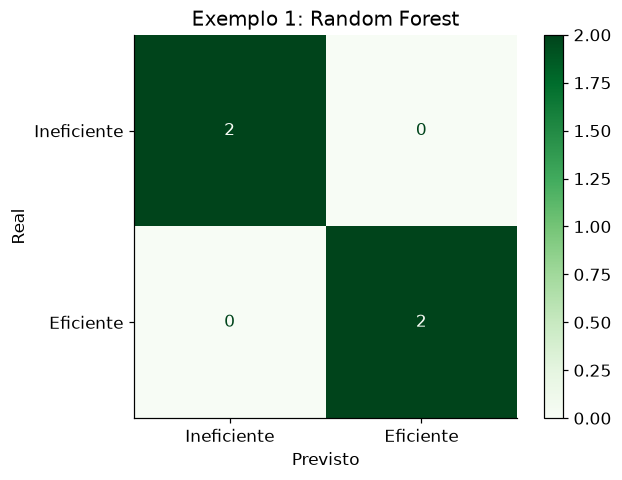

,Modelo,Acurácia,Precisão,Recall,F1-score
0,Árvore de Decisão,1.0,1.0,1.0,1.0
1,Random Forest,1.0,1.0,1.0,1.0


In [24]:
fig, ax = plt.subplots(figsize=(6, 4.5))
ConfusionMatrixDisplay.from_predictions(y_teste, previsao_rf, labels=[0, 1],
    display_labels=["Ineficiente", "Eficiente"], cmap="Greens", values_format="d", colorbar=True, ax=ax)
ax.set(title="Exemplo 1: Random Forest", xlabel="Previsto", ylabel="Real")
plt.tight_layout()
plt.show()
modelos = {"Árvore de Decisão": modelo_arvore, "Random Forest": modelo_rf}
resultados = []
for nome, modelo in modelos.items():
    previsao = modelo.predict(X_teste)
    resultados.append({"Modelo": nome,
        "Acurácia": accuracy_score(y_teste, previsao),
        "Precisão": precision_score(y_teste, previsao, zero_division=0),
        "Recall": recall_score(y_teste, previsao, zero_division=0),
        "F1-score": f1_score(y_teste, previsao, zero_division=0)})
comparacao_modelos_1 = pd.DataFrame(resultados)
display(comparacao_modelos_1.round(3))

**Interpretação:** se os modelos empatam nos quatro casos, o teste não oferece evidência de superioridade de um deles. A árvore individual é mais simples de explicar. A floresta combina várias regras, mas maior complexidade não garante vantagem nesta base.

## 12. A nova máquina do PDF · página 33

A entrada tem 900 peças e 210 kWh. Preserve os nomes e a ordem das colunas utilizadas no treino. `[0]` seleciona a única previsão retornada; a expressão condicional traduz o código em texto. Sem uma resposta observada para essa nova máquina, a previsão não é um acerto verificado.

In [25]:
nova_maquina = pd.DataFrame({"producao": [900], "energia": [210]})
for nome, modelo in modelos.items():
    classe = modelo.predict(nova_maquina)[0]
    resultado = "Eficiente" if classe == 1 else "Ineficiente"
    print(nome, ":", resultado)

Árvore de Decisão : Eficiente
Random Forest : Eficiente


## 13. Visualizar uma árvore e comparar três · páginas 34–39

`estimators_[0]` acessa a primeira árvore já treinada. A figura mostra um componente, não todas as decisões da floresta.

**Duas profundidades diferentes:** `max_depth` em `plot_tree` limita o desenho. No construtor do classificador, limita o crescimento durante o treinamento. Esconder níveis da figura não altera o modelo.

As páginas 38–39 repetem a primeira árvore das páginas 34–35; essa ocorrência está coberta sem repetir a mesma figura.

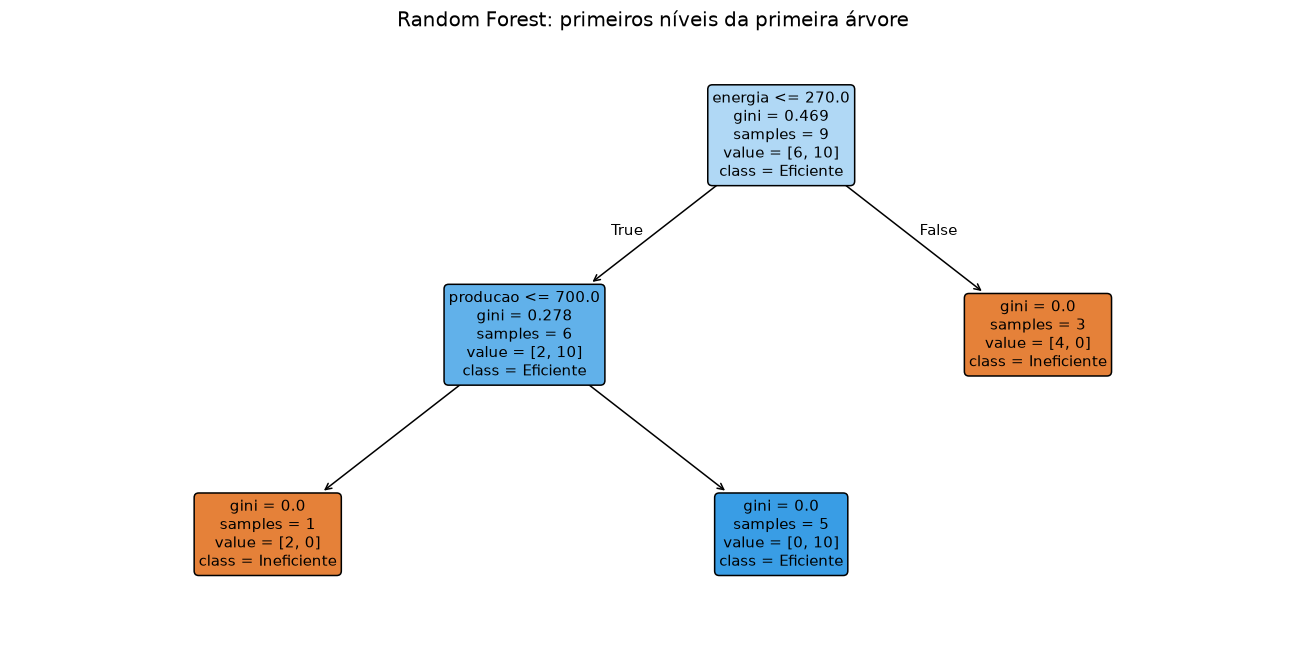

In [26]:
plt.figure(figsize=(12, 6))
plot_tree(modelo_rf.estimators_[0], feature_names=list(X.columns),
    class_names=["Ineficiente", "Eficiente"], filled=True, rounded=True,
    max_depth=2, fontsize=10)
plt.title("Random Forest: primeiros níveis da primeira árvore")
plt.tight_layout()
plt.show()

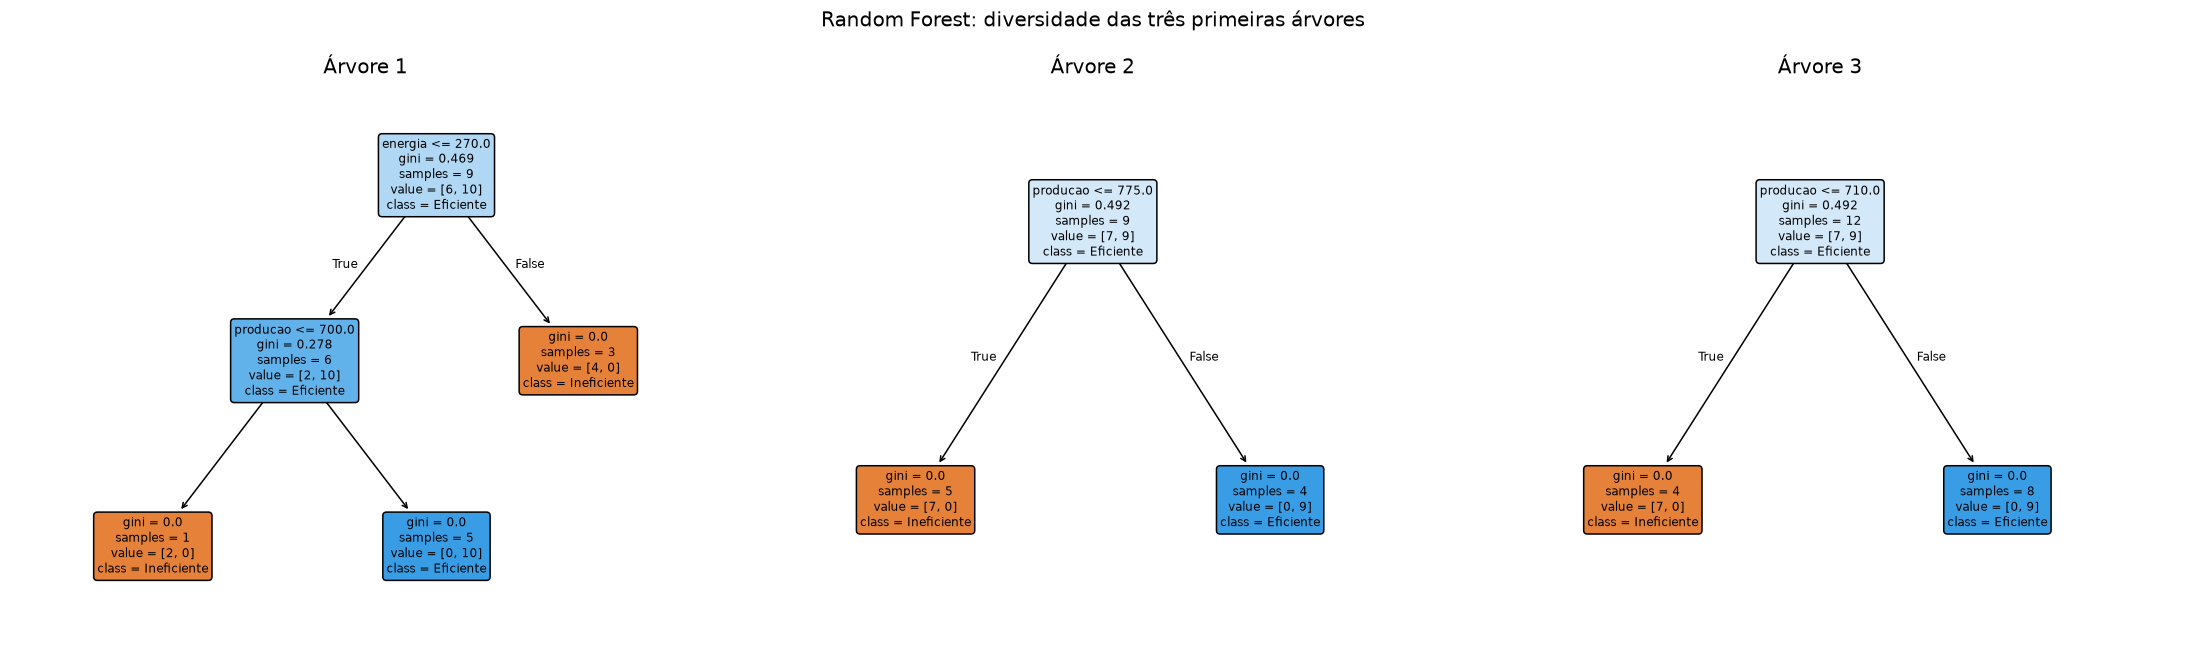

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
for i, ax in enumerate(axes):
    plot_tree(modelo_rf.estimators_[i], feature_names=list(X.columns),
        class_names=["Ineficiente", "Eficiente"], filled=True,
        rounded=True, fontsize=8, ax=ax)
    ax.set_title(f"Árvore {i + 1}")
fig.suptitle("Random Forest: diversidade das três primeiras árvores")
plt.tight_layout()
plt.show()

### Por que `samples` e `value` podem parecer diferentes?

O bootstrap sorteia com reposição. Uma observação pode participar várias vezes. A quantidade de observações distintas e os pesos associados às repetições não precisam coincidir. A exibição de `value` também varia entre versões da biblioteca. Não interprete as repetições como novos registros industriais.

### Complemento: como a floresta combina as respostas

A tabela seguinte mostra as probabilidades de cada árvore para a máquina da página 33. A média deve coincidir com `predict_proba()` da floresta. Probabilidade do modelo não é garantia de acerto nem foi calibrada neste exercício.

In [28]:
import numpy as np
probabilidades_arvores = pd.DataFrame(
    [arvore.predict_proba(nova_maquina.to_numpy())[0] for arvore in modelo_rf.estimators_],
    columns=["P(ineficiente)", "P(eficiente)"])
display(probabilidades_arvores.head(10))
print("Média:", probabilidades_arvores.mean().round(3).to_dict())
print("Probabilidades da floresta:", modelo_rf.predict_proba(nova_maquina).round(3))
assert np.allclose(probabilidades_arvores.mean().to_numpy(), modelo_rf.predict_proba(nova_maquina)[0])

,P(ineficiente),P(eficiente)
0,0.0,1.0
1,0.0,1.0
2,0.0,1.0
3,0.0,1.0
4,0.0,1.0
5,0.0,1.0
6,0.0,1.0
7,0.0,1.0
8,0.0,1.0
9,0.0,1.0


Média: {'P(ineficiente)': 0.0, 'P(eficiente)': 1.0}
Probabilidades da floresta: [[0. 1.]]


### Exercícios da floresta

1. O desenho da primeira árvore explica sozinho a floresta inteira?
2. Por que comparar no mesmo teste?
3. Se uma árvore usa energia, ela contradiz a árvore individual que usou apenas produção?

<details><summary>Respostas comentadas</summary>

1. Não. A previsão final combina os componentes.
2. Para que os dois algoritmos enfrentem os mesmos casos.
3. Não. Amostras bootstrap e seleção aleatória de atributos permitem regras diferentes; importância zero numa árvore não prova irrelevância geral.

</details>

# Parte 2 · Classificação do consumo com tratamento de dados
## 14. Um novo problema e uma nova base · páginas 40–41

Cada registro descreve uma operação em um instante e turno. Queremos prever **consumo alto (1)** ou **baixo (0)** usando características operacionais. Não reutilizamos o rótulo de eficiência das 20 máquinas.

| Campo do CSV | Papel |
|---|---|
| `timestamp` | Conferência de datas; excluído das entradas |
| `turno` | Entrada categórica |
| `producao_unidades` | Entrada numérica |
| `temperatura_ambiente_c` | Entrada numérica, em °C |
| `maquinas_ativas` | Entrada numérica |
| `horas_operacao_turno` | Entrada numérica |
| `consumo_kwh` | Medição histórica usada para criar o alvo |

**Regra da aula:** alto é `consumo_kwh > 400`; baixo é `consumo_kwh <= 400`. O limite é didático, não uma especificação industrial. Alto consumo não significa automaticamente desperdício: uma operação pode consumir mais porque produz mais.

O CSV foi obtido do link da página 40. Mantenha-o na pasta atual do notebook. No Colab, faça upload do CSV para a pasta atual; a leitura em pandas funciona da mesma maneira. O código não depende de recursos exclusivos do Colab.

In [29]:
from pathlib import Path
import sys
import sklearn
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import classification_report
from sklearn.base import clone
print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__, "| scikit-learn:", sklearn.__version__)
CAMINHO_CSV = Path("consumo_energetico_alunos.csv")
if not CAMINHO_CSV.is_file():
    raise FileNotFoundError("Coloque consumo_energetico_alunos.csv na pasta atual ou ajuste CAMINHO_CSV.")
dados_brutos = pd.read_csv(CAMINHO_CSV)
display(dados_brutos.head())

Python: 3.12.14
pandas: 3.0.1 | scikit-learn: 1.9.1


,timestamp,turno,producao_unidades,temperatura_ambiente_c,maquinas_ativas,horas_operacao_turno,consumo_kwh
0,2026-10-12 22:00:00,noite,1102.0,21.80,7.0,4.86,283.36
1,2027-11-15 14:00:00,tarde,1356.0,21.31,6.0,6.90,335.73
2,2028-12-27 06:00:00,manha,796.0,28.89,3.0,6.74,197.15
3,2027-04-25 14:00:00,tarde,1406.0,22.52,7.0,6.05,291.80
4,2028-03-27 06:00:00,manha,1431.0,23.98,7.0,5.44,269.41


## 15. Explorar antes de limpar · páginas 42–44

`shape` retorna linhas e colunas; `dtypes` mostra tipos; `isna().sum()` conta ausências; `duplicated().sum()` conta repetições exatas; `value_counts()` resume categorias; `describe()` calcula estatísticas numéricas. `info()` reúne tipos e valores presentes.

O CSV bruto tem **5.050 linhas e sete colunas**. O print de oito colunas na página 42 não corresponde à estrutura bruta mostrada nas páginas seguintes. Uma coluna criada depois muda essa contagem; aqui calculamos o tamanho em cada etapa.

In [30]:
print(f"Linhas: {len(dados_brutos)} | Colunas: {len(dados_brutos.columns)}")
print("Tipos:")
print(dados_brutos.dtypes)
print("Ausentes:")
print(dados_brutos.isna().sum())
print("Duplicatas exatas:", dados_brutos.duplicated().sum())
print("Turnos:")
print(dados_brutos["turno"].value_counts(dropna=False))
display(dados_brutos.select_dtypes(include="number").describe().round(2))
dados_brutos.info()

Linhas: 5050 | Colunas: 7
Tipos:
timestamp                     str
turno                         str
producao_unidades         float64
temperatura_ambiente_c    float64
maquinas_ativas           float64
horas_operacao_turno      float64
consumo_kwh               float64
dtype: object
Ausentes:
timestamp                  0
turno                      0
producao_unidades         51
temperatura_ambiente_c    50
maquinas_ativas           50
horas_operacao_turno      51
consumo_kwh                0
dtype: int64
Duplicatas exatas: 50
Turnos:
turno
manha    1685
tarde    1683
noite    1682
Name: count, dtype: int64


,producao_unidades,temperatura_ambiente_c,maquinas_ativas,horas_operacao_turno,consumo_kwh
count,4999.00,5000.00,5000.00,4999.00,5050.00
mean,1902.49,26.33,8.97,5.99,399.25
std,940.45,6.21,3.74,1.16,176.52
min,311.00,14.00,3.00,4.00,71.97
25%,1152.00,23.01,6.00,4.98,252.84
50%,1821.00,26.12,9.00,5.99,384.32
75%,2505.00,29.21,12.00,6.99,519.82
max,11239.63,124.86,15.00,8.00,884.82


<class 'pandas.DataFrame'>
RangeIndex: 5050 entries, 0 to 5049
Data columns (total 7 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   timestamp               5050 non-null   str    
 1   turno                   5050 non-null   str    
 2   producao_unidades       4999 non-null   float64
 3   temperatura_ambiente_c  5000 non-null   float64
 4   maquinas_ativas         5000 non-null   float64
 5   horas_operacao_turno    4999 non-null   float64
 6   consumo_kwh             5050 non-null   float64
dtypes: float64(5), str(2)
memory usage: 276.3 KB


## 16. Duplicatas, datas e valores extremos · página 45

Uma duplicata exata repete os valores de todas as colunas. Ela pode fazer a mesma observação aparecer no treino e no teste. Vamos removê-la antes da separação e registrar a quantidade retirada.

**Correção do fluxo do slide:** a página 45 cria `df1 = df.drop_duplicates()`, mas continua as operações em `df`. Aqui usamos de fato a tabela sem duplicatas, `dados_limpos`, nas etapas seguintes. Isso muda o tamanho do teste e pode mudar as métricas.

`errors="coerce"` transforma datas inválidas em `NaT`, permitindo contá-las. Temperaturas acima de 50 °C são apenas sinalizadas para investigação, conforme o material. Não apagamos extremos automaticamente: podem ser erros, eventos reais ou mudanças de processo. As ausências das entradas serão tratadas dentro do pipeline.

In [31]:
dados_limpos = dados_brutos.drop_duplicates().copy()
removidas = len(dados_brutos) - len(dados_limpos)
dados_limpos["timestamp"] = pd.to_datetime(dados_limpos["timestamp"], errors="coerce")
print("Duplicatas removidas:", removidas)
print("Registros restantes:", len(dados_limpos))
print("Datas inválidas:", dados_limpos["timestamp"].isna().sum())
print("Temperaturas > 50 °C para investigar:", (dados_limpos["temperatura_ambiente_c"] > 50).sum())
print("Consumos <= 0:", (dados_limpos["consumo_kwh"] <= 0).sum())
assert not dados_limpos.duplicated().any()
display(dados_limpos.loc[dados_limpos["temperatura_ambiente_c"] > 50].head())

Duplicatas removidas: 50
Registros restantes: 5000
Datas inválidas: 0
Temperaturas > 50 °C para investigar: 25
Consumos <= 0: 0


,timestamp,turno,producao_unidades,temperatura_ambiente_c,maquinas_ativas,horas_operacao_turno,consumo_kwh
523,2026-09-09 14:00:00,tarde,887.0,91.80,4.0,5.99,183.75
531,2030-05-08 22:00:00,noite,2383.0,87.76,13.0,5.12,446.56
713,2026-02-28 06:00:00,manha,3447.0,62.13,15.0,6.57,692.04
960,2030-01-25 06:00:00,manha,2526.0,107.61,11.0,6.36,515.20
1258,2029-01-06 22:00:00,noite,1615.0,65.57,9.0,4.99,348.20


## 17. Boxplots: distribuição e extremos · páginas 46–47

A linha central é a mediana e a caixa vai do primeiro ao terceiro quartil. Os bigodes chegam, em geral, aos valores dentro de 1,5 vezes a amplitude interquartil além da caixa. Pontos externos são candidatos à investigação, não erros comprovados.

Faremos os três boxplots e o gráfico isolado da produção, como nos slides. O gráfico isolado usa pandas/matplotlib em vez de seaborn para evitar uma dependência adicional; o objetivo estatístico é o mesmo.

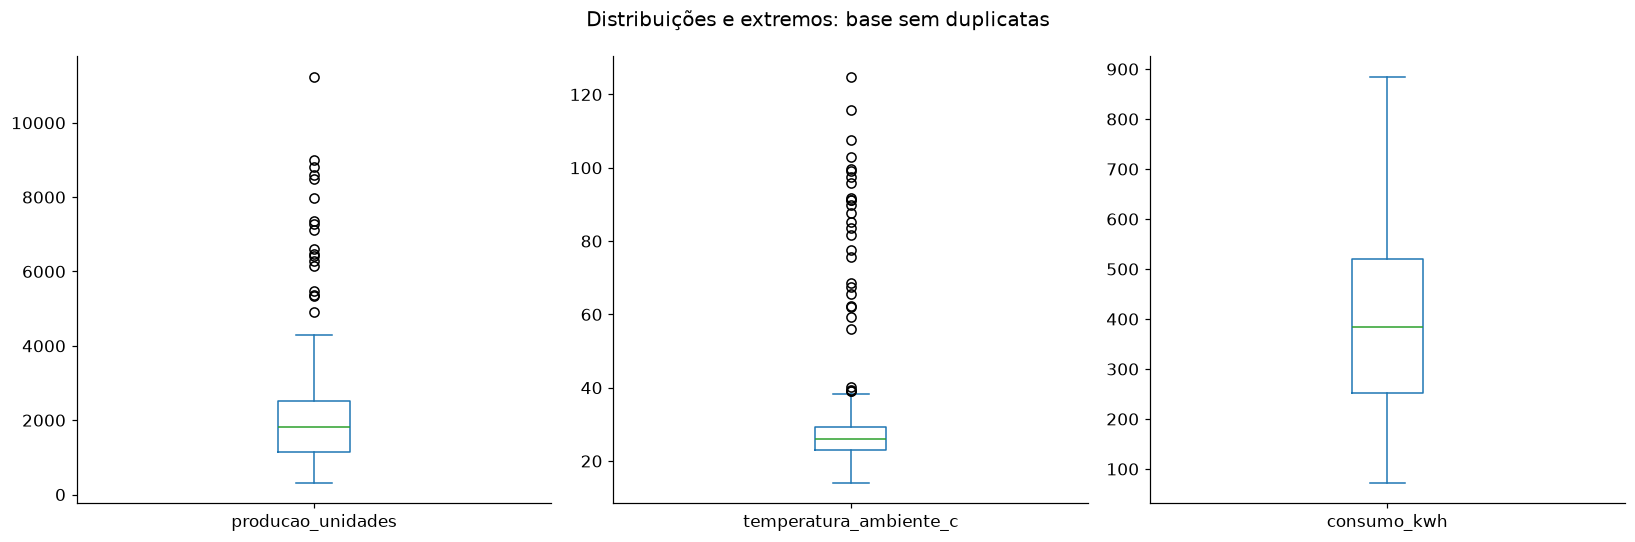

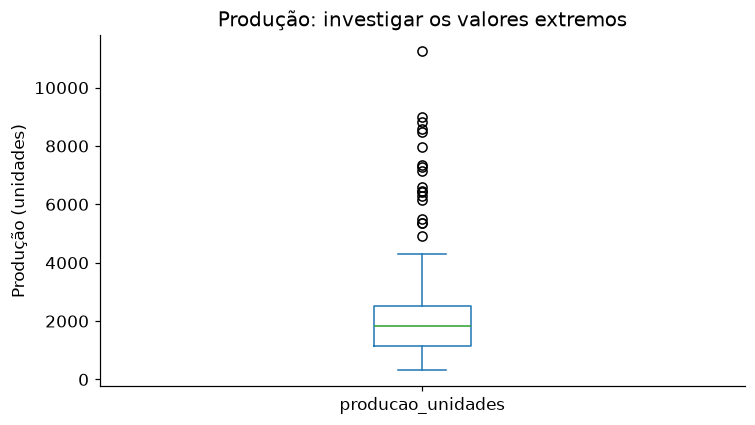

In [32]:
colunas_boxplot = ["producao_unidades", "temperatura_ambiente_c", "consumo_kwh"]
dados_limpos[colunas_boxplot].plot(kind="box", subplots=True, layout=(1, 3), figsize=(15, 5), sharey=False)
plt.suptitle("Distribuições e extremos: base sem duplicatas")
plt.tight_layout()
plt.show()
fig, ax = plt.subplots(figsize=(7, 4))
dados_limpos[["producao_unidades"]].plot.box(ax=ax)
ax.set(title="Produção: investigar os valores extremos", ylabel="Produção (unidades)")
plt.tight_layout()
plt.show()

## 18. Criar o alvo de classificação · páginas 48–49

A comparação `> 400` produz booleanos. `.astype(int)` transforma `False` em 0 e `True` em 1. O consumo precisa estar disponível para criar rótulos históricos. Não preencheremos uma resposta ausente com uma estimativa e depois a trataremos como verdade.

**Vazamento:** se `consumo_kwh` entrasse em `X`, o modelo receberia a medição que determina a resposta. Usamos apenas características operacionais; numa aplicação real, também precisamos confirmar quando elas ficam disponíveis.

consumo_alto
Baixo    2639
Alto     2361
Name: count, dtype: int64


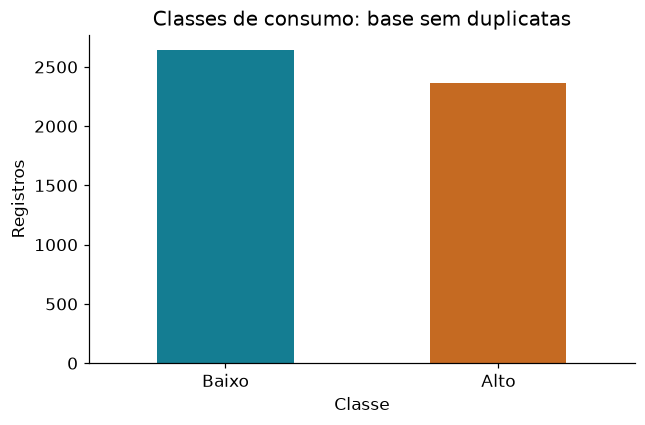

In [33]:
assert dados_limpos["consumo_kwh"].notna().all(), "Investigue as respostas ausentes."
LIMIAR_CONSUMO = 400
dados_limpos["consumo_alto"] = (dados_limpos["consumo_kwh"] > LIMIAR_CONSUMO).astype(int)
contagem_consumo = dados_limpos["consumo_alto"].value_counts().sort_index().rename(index={0: "Baixo", 1: "Alto"})
print(contagem_consumo)
fig, ax = plt.subplots(figsize=(6, 4))
contagem_consumo.plot.bar(ax=ax, color=["#147d92", "#c56a22"], rot=0)
ax.set(title="Classes de consumo: base sem duplicatas", xlabel="Classe", ylabel="Registros")
plt.tight_layout()
plt.show()

## 19. Média, mediana e imputação · páginas 50–54

A **média** soma valores e divide pela quantidade; a **mediana** é o valor central após ordenação. Uma observação extrema desloca mais a média. Assim, a mediana pode ser mais robusta para entradas com assimetria ou extremos.

Exemplo autoral: `[10, 11, 12, 13, 100]` tem média 29,2 e mediana 12. Isso não torna a mediana universalmente melhor: a escolha depende do processo e deve ser avaliada sem selecionar estratégias pelo teste final.

`dropna()` remove ausências apenas da série desenhada, sem descartar as linhas da base de treinamento. O histograma mostra frequências e as linhas verticais indicam média e mediana dos valores observados.

A exploração usa a base inteira para reproduzir a atividade. A estratégia de imputação fica fixada na mediana indicada no material e será ajustada exclusivamente no treino.

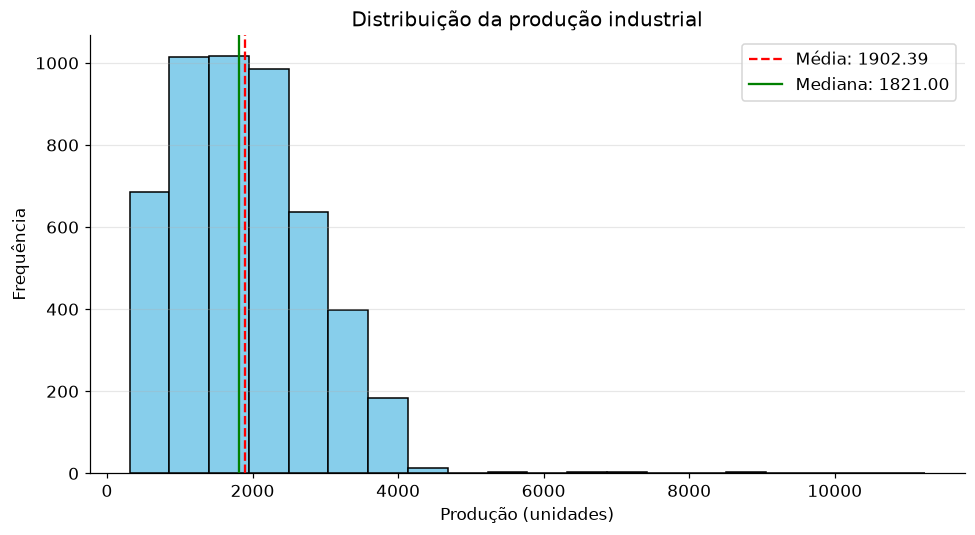

Exemplo autoral - média: 29.2 | mediana: 12.0


In [34]:
serie_producao = dados_limpos["producao_unidades"].dropna()
media = serie_producao.mean()
mediana = serie_producao.median()
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(serie_producao, bins=20, color="skyblue", edgecolor="black")
ax.axvline(media, color="red", linestyle="--", label=f"Média: {media:.2f}")
ax.axvline(mediana, color="green", label=f"Mediana: {mediana:.2f}")
ax.set(title="Distribuição da produção industrial", xlabel="Produção (unidades)", ylabel="Frequência")
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()
exemplo_extremo = pd.Series([10, 11, 12, 13, 100])
print("Exemplo autoral - média:", exemplo_extremo.mean(), "| mediana:", exemplo_extremo.median())

## 20. Selecionar entradas e dividir os dados · página 55

Há quatro entradas numéricas e uma categórica. `timestamp`, `consumo_kwh` e `consumo_alto` não são preditores.

A remoção efetiva das duplicatas deixa 5.000 registros: **4.000 para treino e 1.000 para teste**. Os slides mostram 4.040 e 1.010, pois o treinamento apresentado preservou as 5.050 linhas. A diferença é intencional e verificável.

In [35]:
numericas = ["producao_unidades", "temperatura_ambiente_c", "maquinas_ativas", "horas_operacao_turno"]
categoricas = ["turno"]
atributos = numericas + categoricas
X_consumo = dados_limpos[atributos]
y_consumo = dados_limpos["consumo_alto"]
Xc_treino, Xc_teste, yc_treino, yc_teste = train_test_split(
    X_consumo, y_consumo, test_size=0.20, random_state=42, stratify=y_consumo)
assert set(Xc_treino.index).isdisjoint(Xc_teste.index)
assert "consumo_kwh" not in Xc_treino.columns
print("Treino:", len(Xc_treino), "| Teste:", len(Xc_teste))
display(pd.DataFrame({"treino": yc_treino.value_counts(), "teste": yc_teste.value_counts()}).sort_index())

Treino: 4000 | Teste: 1000


,treino,teste
consumo_alto,,
0,2111,528
1,1889,472


### O pipeline explicado por dentro

**Caminho de uma observação:** números → preencher ausências; turno → codificar categorias; juntar os resultados → classificador.

| Componente | Durante `fit()` | Durante `predict()` |
|---|---|---|
| `SimpleImputer` | Aprende as medianas do treino | Preenche ausências com essas medianas |
| `OneHotEncoder` | Aprende categorias do treino | Cria indicadores dos turnos |
| `ColumnTransformer` | Ajusta transformações por colunas | Aplica e combina resultados |
| `Pipeline` | Ajusta preparação e classificador | Prepara entradas e prevê |

**One-hot:** em vez de criar uma ordem artificial manhã=1, tarde=2, noite=3, usamos indicadores separados. `handle_unknown="ignore"` codifica uma categoria desconhecida com zeros nesse bloco. A previsão funciona, mas a qualidade para esse turno não está demonstrada.

As medianas não são recalculadas no teste. Por isso não usamos `fillna(df.mean())` na tabela inteira antes de separar.

O classificador da aula é uma árvore com `max_depth=4`. Usamos nomes diferentes entre exemplos para preservar a árvore das 20 máquinas.

In [36]:
preprocessamento = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), numericas),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categoricas)
])
modelo_consumo = Pipeline([
    ("preparacao", clone(preprocessamento)),
    ("arvore", DecisionTreeClassifier(max_depth=4, random_state=42))
])
modelo_consumo.fit(Xc_treino, yc_treino)
previsoes_consumo = modelo_consumo.predict(Xc_teste)
print("Árvore de consumo treinada.")

Árvore de consumo treinada.


### Complemento: inspecionar o que a preparação aprendeu

Os nomes transformados mostram números e indicadores de turno. Comparamos as medianas do imputador com as calculadas diretamente no treino: devem coincidir. Não precisamos consultar medianas do teste para fazer a verificação.

In [37]:
preparacao_ajustada = modelo_consumo.named_steps["preparacao"]
nomes_transformados = preparacao_ajustada.get_feature_names_out()
print("Entradas após preparação:", list(nomes_transformados))
medianas_aprendidas = preparacao_ajustada.named_transformers_["num"].statistics_
display(pd.DataFrame({"mediana_no_pipeline": medianas_aprendidas,
    "mediana_do_treino": Xc_treino[numericas].median().to_numpy()}, index=numericas))
assert np.allclose(medianas_aprendidas, Xc_treino[numericas].median().to_numpy())
print("Ausências originais no teste:", int(Xc_teste.isna().sum().sum()))
print("Ausências após preparação:", int(np.isnan(preparacao_ajustada.transform(Xc_teste)).sum()))

Entradas após preparação: ['num__producao_unidades', 'num__temperatura_ambiente_c', 'num__maquinas_ativas', 'num__horas_operacao_turno', 'cat__turno_manha', 'cat__turno_noite', 'cat__turno_tarde']


,mediana_no_pipeline,mediana_do_treino
producao_unidades,1822.00,1822.00
temperatura_ambiente_c,26.12,26.12
maquinas_ativas,9.00,9.00
horas_operacao_turno,5.98,5.98


Ausências originais no teste: 48
Ausências após preparação: 0


## 21. Avaliar a árvore de consumo · páginas 56–57

A classe positiva agora é **Alto**, enquanto no exemplo 1 era **Eficiente**. As fórmulas são as mesmas; muda a interpretação do erro.

`classification_report` mostra precisão, recall, F1 e `support` por classe. Support é a quantidade de respostas reais de cada classe no teste. `macro avg` dá peso igual às classes; `weighted avg` pondera pelos supports. Nenhuma média substitui analisar o erro relevante para o processo.

A função `avaliar` reutiliza o procedimento nos dois modelos e retorna métricas para comparação. A matriz mantém linhas reais, colunas previstas e ordem `[Baixo, Alto]`.

=== Árvore: consumo alto/baixo ===
Acurácia: 0.964
Precisão: 0.972
Recall: 0.951
F1-score: 0.961
              precision    recall  f1-score   support

       Baixo       0.96      0.98      0.97       528
        Alto       0.97      0.95      0.96       472

    accuracy                           0.96      1000
   macro avg       0.96      0.96      0.96      1000
weighted avg       0.96      0.96      0.96      1000



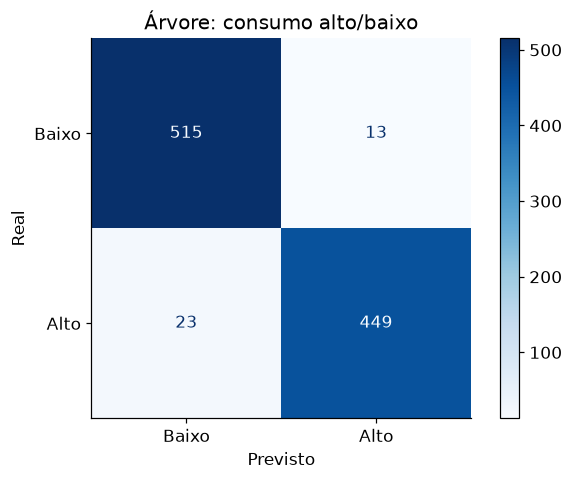

In [38]:
def avaliar(nome, verdadeiro, previsto, rotulos=("Baixo", "Alto")):
    metricas = {"Modelo": nome,
        "Acurácia": accuracy_score(verdadeiro, previsto),
        "Precisão": precision_score(verdadeiro, previsto, zero_division=0),
        "Recall": recall_score(verdadeiro, previsto, zero_division=0),
        "F1-score": f1_score(verdadeiro, previsto, zero_division=0)}
    print(f"=== {nome} ===")
    for chave, valor in metricas.items():
        if chave != "Modelo": print(f"{chave}: {valor:.3f}")
    print(classification_report(verdadeiro, previsto, labels=[0, 1],
        target_names=list(rotulos), zero_division=0))
    fig, ax = plt.subplots(figsize=(6, 4.5))
    ConfusionMatrixDisplay.from_predictions(verdadeiro, previsto, labels=[0, 1],
        display_labels=list(rotulos), cmap="Blues", values_format="d", colorbar=True, ax=ax)
    ax.set(title=nome, xlabel="Previsto", ylabel="Real")
    plt.tight_layout()
    plt.show()
    tn, fp, fn, tp = confusion_matrix(verdadeiro, previsto, labels=[0, 1]).ravel()
    metricas.update({"FP": int(fp), "FN": int(fn), "Erros": int(fp + fn)})
    return metricas

avaliacao_arvore_consumo = avaliar("Árvore: consumo alto/baixo", yc_teste, previsoes_consumo)

## 22. Primeiros níveis da árvore · páginas 58–59

Os nomes começam por `num__` ou `cat__` para identificar o bloco da preparação. A árvore recebe as colunas transformadas, não os textos dos turnos.

O modelo tem profundidade máxima 4 e a figura mostra até profundidade 2. Reticências indicam ramos que continuam. Divisões e contagens são recalculadas na base limpa; não devem ser copiadas do slide.

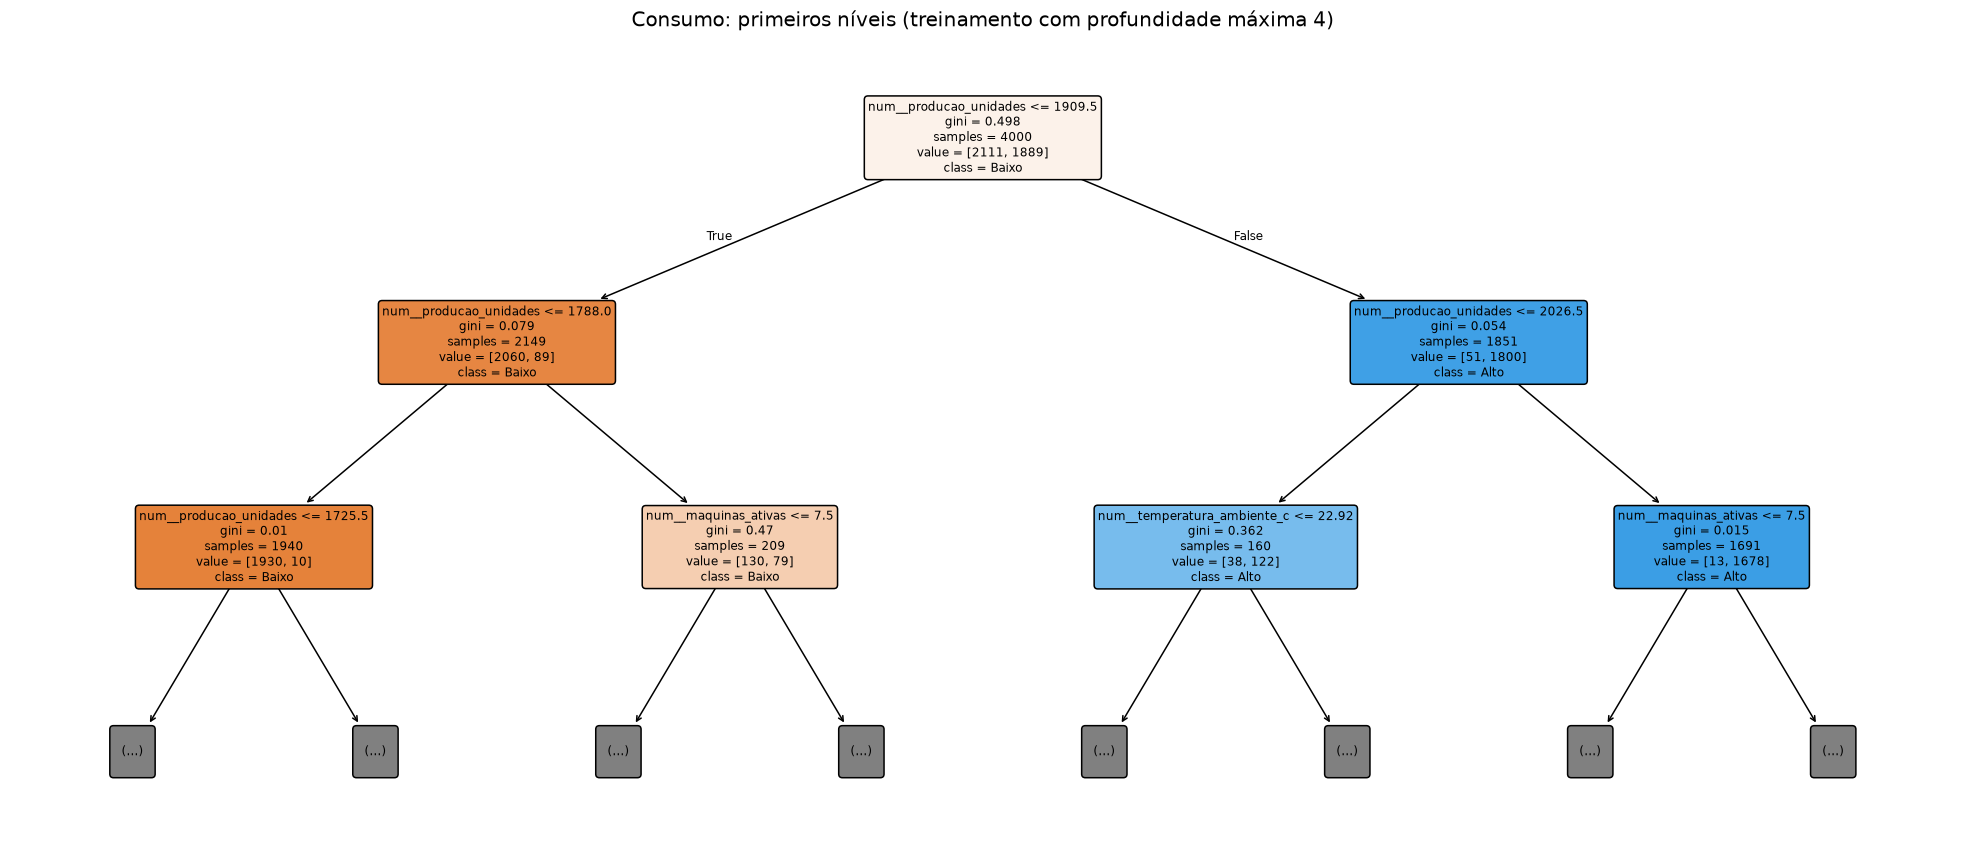

In [39]:
plt.figure(figsize=(18, 8))
plot_tree(modelo_consumo.named_steps["arvore"], feature_names=nomes_transformados,
    class_names=["Baixo", "Alto"], filled=True, rounded=True, fontsize=8, max_depth=2)
plt.title("Consumo: primeiros níveis (treinamento com profundidade máxima 4)")
plt.tight_layout()
plt.show()

## 23. Segundo classificador: Random Forest · páginas 60–63

Preservamos entradas e divisão. A floresta usa 100 árvores com profundidade máxima 5. `clone(preprocessamento)` cria preparação independente para cada pipeline, evitando compartilhar um objeto ajustável entre os dois modelos.

Ambos aprendem imputação e categorias somente no treino. Os resultados abaixo são os calculados na base limpa, não percentuais transcritos do PDF.

=== Random Forest: consumo alto/baixo ===
Acurácia: 0.966
Precisão: 0.968
Recall: 0.960
F1-score: 0.964
              precision    recall  f1-score   support

       Baixo       0.96      0.97      0.97       528
        Alto       0.97      0.96      0.96       472

    accuracy                           0.97      1000
   macro avg       0.97      0.97      0.97      1000
weighted avg       0.97      0.97      0.97      1000



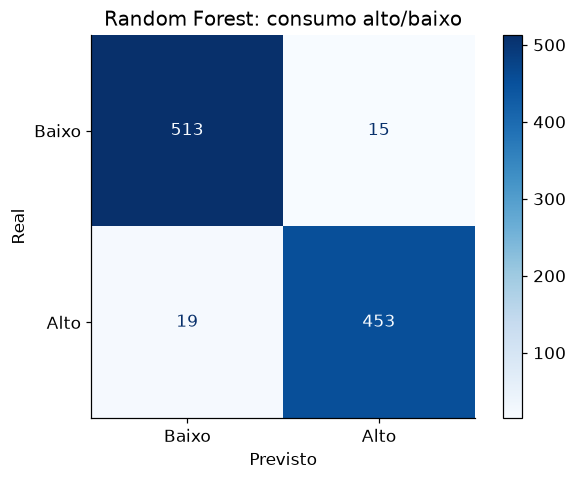

In [40]:
modelo_rf_consumo = Pipeline([
    ("preparacao", clone(preprocessamento)),
    ("floresta", RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42))
])
modelo_rf_consumo.fit(Xc_treino, yc_treino)
previsoes_rf_consumo = modelo_rf_consumo.predict(Xc_teste)
avaliacao_rf_consumo = avaliar("Random Forest: consumo alto/baixo", yc_teste, previsoes_rf_consumo)

## 24. Comparar desempenho e erros · página 64

Observe acurácia, precisão, recall, F1 e quantidades de falsos positivos e negativos. Uma diferença pequena de acurácia, sozinha, não estabelece superioridade consistente.

O PDF relata 96,9% e 97,1% sobre 1.010 registros. Nossa limpeza muda a divisão para 1.000 casos de teste. Os números podem diferir: compare os resultados calculados e preserve a comparação metodológica.

,Modelo,Acurácia,Precisão,Recall,F1-score,FP,FN,Erros
0,Árvore: consumo alto/baixo,0.964,0.9719,0.9513,0.9615,13,23,36
1,Random Forest: consumo alto/baixo,0.966,0.9679,0.9597,0.9638,15,19,34


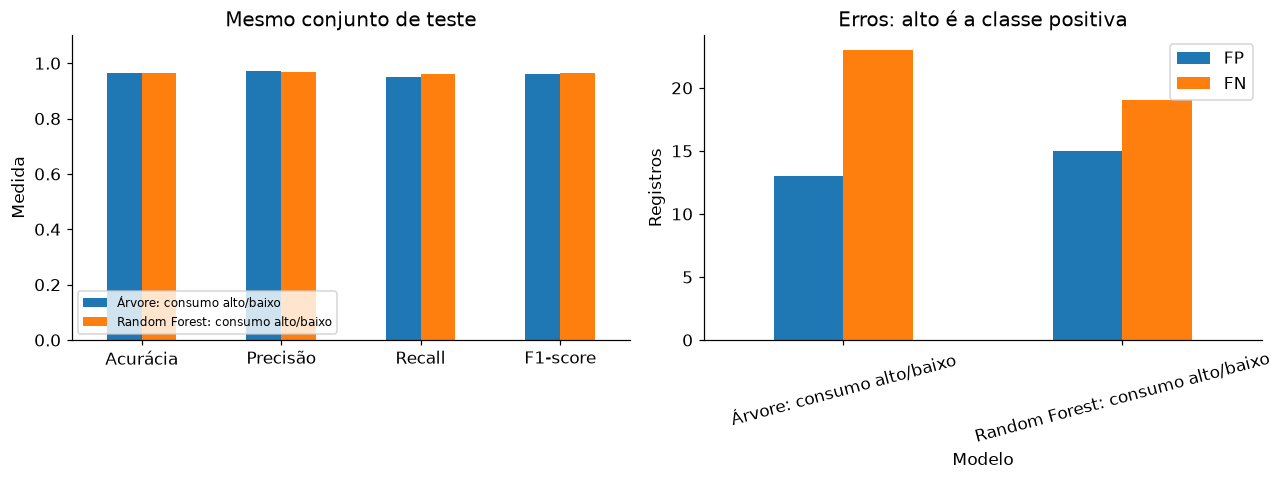

In [41]:
comparacao_consumo = pd.DataFrame([avaliacao_arvore_consumo, avaliacao_rf_consumo])
display(comparacao_consumo.round(4))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
comparacao_consumo.set_index("Modelo")[["Acurácia", "Precisão", "Recall", "F1-score"]].T.plot.bar(ax=axes[0], rot=0)
axes[0].set(ylim=(0, 1.1), ylabel="Medida", title="Mesmo conjunto de teste")
axes[0].legend(fontsize=8, loc="lower left")
comparacao_consumo.set_index("Modelo")[["FP", "FN"]].plot.bar(ax=axes[1], rot=15)
axes[1].set(ylabel="Registros", title="Erros: alto é a classe positiva")
plt.tight_layout()
plt.show()

## 25. Qual erro custa mais? · página 65

- **FP:** consumo real baixo, previsto como alto. Pode gerar investigação desnecessária.
- **FN:** consumo real alto, previsto como baixo. Pode deixar passar uma situação que exigiria ação.

A resposta depende do custo de investigar, do custo da energia, da possibilidade de agir e das consequências de um caso não identificado. Defina isso com quem toma a decisão.

### Complemento: simular custos

Os pesos são **hipotéticos**, em unidades de custo por erro. Não representam estimativas financeiras de uma fábrica. Altere-os e observe se a preferência muda. O cálculo cobre somente os dois tipos de erro no teste; não inclui implementação, operação ou incerteza.

In [42]:
CUSTO_FP = 1.0
CUSTO_FN = 5.0
comparacao_custos = comparacao_consumo[["Modelo", "FP", "FN"]].copy()
comparacao_custos["custo_hipotetico_no_teste"] = comparacao_custos["FP"] * CUSTO_FP + comparacao_custos["FN"] * CUSTO_FN
display(comparacao_custos.sort_values("custo_hipotetico_no_teste"))

,Modelo,FP,FN,custo_hipotetico_no_teste
1,Random Forest: consumo alto/baixo,15,19,110.0
0,Árvore: consumo alto/baixo,13,23,128.0


## 26. Complemento: prever um cenário novo com o pipeline

A temperatura pode estar ausente: o pipeline aplica a mediana do treino. Não envie consumo medido nem classe desejada. Os números são um cenário inventado, sem resposta observada para verificar o acerto.

Você pode testar um turno desconhecido. O encoder permite a execução, mas isso não demonstra boa previsão para essa categoria. A probabilidade exibida é uma saída do modelo, sem calibração verificada.

In [43]:
cenario_consumo = pd.DataFrame({
    "producao_unidades": [2000.0], "temperatura_ambiente_c": [np.nan],
    "maquinas_ativas": [6.0], "horas_operacao_turno": [7.0], "turno": ["tarde"]})
display(cenario_consumo)
for nome, modelo in {"Árvore": modelo_consumo, "Random Forest": modelo_rf_consumo}.items():
    classe = int(modelo.predict(cenario_consumo)[0])
    prob_alto = modelo.predict_proba(cenario_consumo)[0, list(modelo.classes_).index(1)]
    print(f"{nome}: {'Alto' if classe else 'Baixo'} | Probabilidade de modelo para Alto: {prob_alto:.1%}")

,producao_unidades,temperatura_ambiente_c,maquinas_ativas,horas_operacao_turno,turno
0,2000.0,NaN,6.0,7.0,tarde


Árvore: Alto | Probabilidade de modelo para Alto: 84.8%
Random Forest: Baixo | Probabilidade de modelo para Alto: 44.8%


## 27. Programação tradicional e Machine Learning · página 66

| Abordagem | O que fornecemos | Resultado |
|---|---|---|
| Regra tradicional | `consumo_kwh > 400` | Classe histórica calculada da medição |
| Treinamento supervisionado | Entradas operacionais, rótulos e algoritmo | Modelo ajustado |
| Inferência | Novas entradas e modelo ajustado | Previsão sem fornecer consumo medido |

As abordagens convivem no exercício: uma regra cria o alvo e o modelo aprende a estimá-lo usando outras variáveis. Se o consumo já estiver disponível na decisão, a regra direta resolve a classificação. O modelo faz sentido para estimá-la sem essa medição, desde que as entradas estejam disponíveis.

### O que falta para uma aplicação real?

Confirme a qualidade dos rótulos, investigue extremos, verifique quando os atributos ficam disponíveis e planeje teste compatível com o uso. Prever períodos futuros pode exigir separação temporal. Registros da mesma máquina ou processo podem exigir separação por grupos.

A divisão aleatória estratificada segue a atividade do PDF, mas não substitui validação operacional. Alto consumo e eficiência são problemas diferentes.

## 28. Exercícios finais — resolução

**Aluno: Carlos Pereira**  
**Disciplina: Data Science e Big Data | Professor: Daniel Vieira**

**Apresentação no Google Colab:** as respostas estão em células de texto e os desafios em células de código, com os resultados salvos. Para recalcular, execute o notebook desde o início e carregue o CSV original na pasta de arquivos da sessão.

Nesta atividade, analisei os dois problemas apresentados na aula: a classificação da eficiência de máquinas e a classificação do consumo energético. A seguir, apresento as respostas e os experimentos realizados no notebook.

### 1. Qual é a diferença entre `eficiente` e `consumo_alto`?

No primeiro exemplo, `eficiente` é a classificação já fornecida para cada uma das 20 máquinas: 0 indica ineficiente e 1 indica eficiente. No segundo exemplo, criei `consumo_alto` a partir da medição de energia: valores acima de 400 kWh recebem 1 e os demais recebem 0.

Portanto, os alvos representam conceitos diferentes. Uma operação com consumo alto pode estar produzindo mais e não ser necessariamente ineficiente. O limite de 400 kWh é uma regra didática da atividade.

### 2. Por que o teste passou de 1.010 para 1.000 registros?

O arquivo original contém 5.050 linhas. Identifiquei e removi 50 duplicatas exatas, ficando com 5.000 registros. Como reservei 20% para teste, obtive `5.000 × 0,20 = 1.000` registros de teste e 4.000 de treinamento.

No código do slide, a tabela sem duplicatas é criada em outra variável, mas as etapas seguintes continuam usando a tabela original. Nesta implementação, utilizei a base sem duplicatas para reduzir o risco de uma mesma observação aparecer no treino e no teste. Por isso, também recalculei as métricas.

### 3. Por que excluí `consumo_kwh` das entradas?

Usei `consumo_kwh` somente para criar a resposta histórica. Se essa coluna também entrasse no modelo, ele receberia a própria informação que determina o alvo, causando vazamento de informação.

Para prever a classe, utilizei produção, temperatura ambiente, máquinas ativas, horas de operação e turno. Assim, o modelo precisa aprender a relação entre as condições operacionais e a classe de consumo.

### 4. De onde vem a mediana utilizada no teste?

A mediana é calculada com os dados de treinamento pelo `SimpleImputer`, dentro do pipeline. Depois do ajuste, o mesmo valor é aplicado às ausências no teste e nos novos cenários.

Não calculei uma nova mediana com o teste. Dessa forma, os dados reservados para avaliação não participam da preparação aprendida pelo modelo.

### 5. `max_depth=2` em `plot_tree` reduz a complexidade do modelo?

Não. Nesse comando, o parâmetro limita apenas os níveis exibidos no desenho. O modelo continua usando todos os níveis aprendidos no treinamento.

Para limitar o crescimento da árvore, é necessário definir `max_depth` no classificador. Nesta atividade, a árvore do segundo exemplo foi treinada com profundidade máxima 4, enquanto sua figura mostra somente até o nível 2.

### 6. O que acontece com um turno desconhecido?

Configurei `OneHotEncoder(handle_unknown="ignore")`. Quando chega um turno que não apareceu no treinamento, o bloco de indicadores desse atributo fica com zeros e o pipeline consegue executar a previsão.

Isso evita um erro de execução, mas não comprova que a previsão será adequada para esse turno. Em uma aplicação real, eu investigaria a nova categoria e avaliaria a necessidade de atualizar o treinamento.

### 7. Uma temperatura acima de 50 °C deve ser removida automaticamente?

Não. Usei esse limite para sinalizar registros que precisam ser investigados. Uma temperatura elevada pode representar erro de medição, condição real do ambiente ou um evento diferente do padrão.

Antes de excluir o registro, eu verificaria a origem da medição, a unidade, as condições do processo e a avaliação da equipe responsável. Apagar todos os extremos poderia eliminar informações importantes.

### 8. O modelo com maior recall é sempre o melhor?

Não. Recall maior indica que o modelo identificou uma proporção maior dos casos realmente positivos, mas essa vantagem pode vir acompanhada de mais falsos positivos.

Na classificação de consumo, um falso negativo deixa de identificar um consumo alto, enquanto um falso positivo gera um alerta de consumo alto para um caso baixo. A escolha depende do custo e da consequência desses erros, além das demais métricas.

## 29. Desafios práticos — experimentos e análise

### Desafio 1. Alteração dos custos de falsos positivos e negativos

Comparei três situações hipotéticas: custos iguais, falso negativo mais caro e falso positivo mais caro. Mantive as previsões dos modelos e alterei apenas os pesos dos erros.

O cálculo utilizado foi **custo = FP × custo do FP + FN × custo do FN**. Os valores são unidades hipotéticas de custo, sem correspondência com preços reais de uma indústria.

In [44]:
cenarios_custos_finais = {
    "Custos iguais": (1, 1),
    "FN mais caro": (1, 5),
    "FP mais caro": (5, 1)
}
linhas_custos_finais = []
for cenario, (custo_fp, custo_fn) in cenarios_custos_finais.items():
    for _, resultado_modelo in comparacao_consumo.iterrows():
        linhas_custos_finais.append({
            "Cenário": cenario,
            "Modelo": resultado_modelo["Modelo"],
            "FP": int(resultado_modelo["FP"]),
            "FN": int(resultado_modelo["FN"]),
            "Custo de FP": custo_fp,
            "Custo de FN": custo_fn,
            "Custo total": int(resultado_modelo["FP"]) * custo_fp + int(resultado_modelo["FN"]) * custo_fn
        })
tabela_custos_finais = pd.DataFrame(linhas_custos_finais)
display(tabela_custos_finais)
display(tabela_custos_finais.pivot(index="Cenário", columns="Modelo", values="Custo total"))

,Cenário,Modelo,FP,FN,Custo de FP,Custo de FN,Custo total
0,Custos iguais,Árvore: consumo alto/baixo,13,23,1,1,36
1,Custos iguais,Random Forest: consumo alto/baixo,15,19,1,1,34
2,FN mais caro,Árvore: consumo alto/baixo,13,23,1,5,128
3,FN mais caro,Random Forest: consumo alto/baixo,15,19,1,5,110
4,FP mais caro,Árvore: consumo alto/baixo,13,23,5,1,88
5,FP mais caro,Random Forest: consumo alto/baixo,15,19,5,1,94


Modelo,Random Forest: consumo alto/baixo,Árvore: consumo alto/baixo
Cenário,,
Custos iguais,34,36
FN mais caro,110,128
FP mais caro,94,88


**Minha análise:** nesta execução, a árvore apresentou 13 falsos positivos e 23 falsos negativos; a floresta apresentou 15 falsos positivos e 19 falsos negativos.

| Situação | Árvore | Random Forest | Menor custo observado |
|---|---:|---:|---|
| Custos iguais | 36 | 34 | Random Forest |
| FN custa cinco vezes mais | 128 | 110 | Random Forest |
| FP custa cinco vezes mais | 88 | 94 | Árvore |

Quando o falso negativo ficou mais caro, a floresta foi favorecida por deixar passar menos casos de consumo alto. Quando aumentei o custo do falso positivo, a árvore teve menor custo por gerar menos alertas incorretos. Assim, a escolha mudou conforme a consequência do erro.

Esses resultados se referem ao teste desta execução. A análise ilustra a decisão e não comprova uma superioridade geral dos modelos.

### Desafio 2. Alteração de uma variável por vez

Defini um cenário de referência com produção de 2.000 unidades, temperatura de 25 °C, seis máquinas ativas, sete horas de operação e turno da tarde. Em cada outro cenário, alterei somente um desses campos.

Escolhi comparar tanto a classe prevista quanto a probabilidade fornecida pelo modelo para consumo alto. Uma variável pode alterar a probabilidade sem mudar a classe final. Os cenários são simulados e não possuem consumo medido para verificar o acerto.

In [45]:
referencia_final = {
    "producao_unidades": 2000.0,
    "temperatura_ambiente_c": 25.0,
    "maquinas_ativas": 6.0,
    "horas_operacao_turno": 7.0,
    "turno": "tarde"
}
alteracoes_finais = {
    "Referência": {},
    "Produção de 1.000 unidades": {"producao_unidades": 1000.0},
    "Produção de 3.000 unidades": {"producao_unidades": 3000.0},
    "Temperatura de 35 °C": {"temperatura_ambiente_c": 35.0},
    "Nove máquinas ativas": {"maquinas_ativas": 9.0},
    "Quatro horas de operação": {"horas_operacao_turno": 4.0},
    "Turno da noite": {"turno": "noite"}
}
entradas_finais = pd.DataFrame(
    [{**referencia_final, **alteracao} for alteracao in alteracoes_finais.values()],
    index=list(alteracoes_finais)
)[atributos]
display(entradas_finais)
respostas_cenarios_finais = []
for nome, pipeline in {"Árvore": modelo_consumo, "Random Forest": modelo_rf_consumo}.items():
    classes = pipeline.predict(entradas_finais)
    probabilidades = pipeline.predict_proba(entradas_finais)[:, list(pipeline.classes_).index(1)]
    for cenario, classe, probabilidade in zip(entradas_finais.index, classes, probabilidades):
        respostas_cenarios_finais.append({"Cenário": cenario, "Modelo": nome,
            "Classe prevista": "Alto" if classe == 1 else "Baixo",
            "Probabilidade de Alto": round(float(probabilidade), 4)})
tabela_cenarios_finais = pd.DataFrame(respostas_cenarios_finais)
display(tabela_cenarios_finais)
for nome in ["Árvore", "Random Forest"]:
    recorte = tabela_cenarios_finais.loc[tabela_cenarios_finais["Modelo"] == nome].set_index("Cenário")
    classe_referencia = recorte.loc["Referência", "Classe prevista"]
    mudancas = recorte.loc[recorte["Classe prevista"] != classe_referencia].index.tolist()
    print(f"{nome}: referência = {classe_referencia}.")
    print("Cenários com mudança de classe:", "; ".join(mudancas) if mudancas else "Nenhum dos cenários testados.")

,producao_unidades,temperatura_ambiente_c,maquinas_ativas,horas_operacao_turno,turno
Referência,2000.0,25.0,6.0,7.0,tarde
Produção de 1.000 unidades,1000.0,25.0,6.0,7.0,tarde
Produção de 3.000 unidades,3000.0,25.0,6.0,7.0,tarde
Temperatura de 35 °C,2000.0,35.0,6.0,7.0,tarde
Nove máquinas ativas,2000.0,25.0,9.0,7.0,tarde
Quatro horas de operação,2000.0,25.0,6.0,4.0,tarde
Turno da noite,2000.0,25.0,6.0,7.0,noite


,Cenário,Modelo,Classe prevista,Probabilidade de Alto
0,Referência,Árvore,Alto,0.8482
1,Produção de 1.000 unidades,Árvore,Baixo,0.0000
2,Produção de 3.000 unidades,Árvore,Baixo,0.0000
3,Temperatura de 35 °C,Árvore,Alto,0.8482
4,Nove máquinas ativas,Árvore,Alto,0.8482
5,Quatro horas de operação,Árvore,Alto,0.8482
6,Turno da noite,Árvore,Alto,0.8482
7,Referência,Random Forest,Baixo,0.4644
8,Produção de 1.000 unidades,Random Forest,Baixo,0.0284
9,Produção de 3.000 unidades,Random Forest,Baixo,0.4011


Árvore: referência = Alto.
Cenários com mudança de classe: Produção de 1.000 unidades; Produção de 3.000 unidades
Random Forest: referência = Baixo.
Cenários com mudança de classe: Nove máquinas ativas


**Minha análise:** a árvore classificou a referência como consumo alto. Ao reduzir a produção para 1.000 unidades, a previsão passou para baixo. Ao elevar a produção para 3.000 unidades, a árvore também previu baixo. As demais alterações isoladas mantiveram a classe alta nessa árvore.

No Random Forest, a referência foi classificada como baixa, com probabilidade de modelo de aproximadamente 46,4% para alto. A alteração para nove máquinas ativas mudou a previsão para alta, com aproximadamente 88,2%. Nos outros cenários, a classe continuou baixa, embora as probabilidades tenham variado.

O resultado com 3.000 unidades mostra que o modelo não aprendeu uma relação obrigatoriamente crescente entre produção e consumo. Ele segue as divisões e os rótulos encontrados no treinamento, inclusive os padrões de uma base que contém valores extremos mantidos para investigação. Por isso, eu verificaria esse comportamento e os registros envolvidos antes de utilizá-lo numa decisão operacional.

Comparei uma variável por vez para observar a resposta dos modelos. Não interpretei os resultados como prova de causa e efeito nem as probabilidades como garantia de acerto. Esses cenários não têm consumo observado para conferir a classificação.


### Desafio 3. Localização das medianas e previsão de outro cenário

Consultei `named_steps["preparacao"]` e, dentro dele, o transformador numérico. O atributo `statistics_` guarda as medianas aprendidas pelo imputador.

Para verificar se uma nova previsão alteraria esses valores, guardei as medianas antes de prever um cenário com temperatura ausente e comparei com os valores depois da previsão.

In [46]:
imputador_final = modelo_consumo.named_steps["preparacao"].named_transformers_["num"]
medianas_antes_final = imputador_final.statistics_.copy()
cenario_ausente_final = pd.DataFrame([referencia_final])[atributos]
cenario_ausente_final.loc[0, "temperatura_ambiente_c"] = np.nan
classe_ausente_final = modelo_consumo.predict(cenario_ausente_final)[0]
medianas_depois_final = imputador_final.statistics_.copy()
display(pd.DataFrame({"Antes da previsão": medianas_antes_final,
    "Depois da previsão": medianas_depois_final}, index=numericas))
medianas_iguais_final = np.array_equal(medianas_antes_final, medianas_depois_final)
print("As medianas permaneceram iguais?", medianas_iguais_final)
print("Classe do cenário com temperatura ausente:", "Alto" if classe_ausente_final else "Baixo")
assert medianas_iguais_final

,Antes da previsão,Depois da previsão
producao_unidades,1822.00,1822.00
temperatura_ambiente_c,26.12,26.12
maquinas_ativas,9.00,9.00
horas_operacao_turno,5.98,5.98


As medianas permaneceram iguais? True
Classe do cenário com temperatura ausente: Alto


**Minha análise:** as medianas permaneceram iguais. A chamada `predict()` reutilizou a preparação já ajustada; não houve novo treinamento. Portanto, a temperatura ausente foi substituída pela mediana aprendida no treino, sem incorporar os novos cenários ao cálculo.

### Desafio 4. Por que um ponto fora do boxplot não é necessariamente um erro?

Um ponto fora dos bigodes indica uma observação distante da região central segundo o critério estatístico do gráfico. Isso não significa, por si só, que a medição esteja errada. Na indústria, ele pode representar um pico de produção, uma condição operacional diferente ou uma ocorrência que merece atenção. Por esse motivo, mantive os valores extremos para investigação e não os excluí automaticamente. A decisão de removê-los depende da conferência da medição e do conhecimento do processo.

## 30. Conclusão da atividade

No primeiro exemplo, observei como a árvore aprendeu uma regra simples para os rótulos de eficiência das 20 máquinas. Comparei essa árvore com uma floresta e identifiquei que o acerto em apenas quatro registros de teste não comprova desempenho em uma operação real.

No segundo exemplo, trabalhei com a base de consumo energético, removi duplicatas e utilizei pipelines para tratar ausências e codificar o turno sem ajustar essas transformações no teste. A árvore obteve 96,4% de acurácia, com 36 erros, e o Random Forest obteve 96,6%, com 34 erros, sobre os mesmos 1.000 registros reservados.

A floresta apresentou menos falsos negativos, enquanto a árvore gerou menos falsos positivos. A simulação de custos mostrou que o modelo mais adequado depende da consequência de cada tipo de erro. Por isso, considerei as métricas em conjunto com o objetivo da classificação.

O principal aprendizado foi que a qualidade da análise depende de todo o processo: definição do alvo, preparação dos dados, separação do teste, treinamento e interpretação dos resultados. Antes de uma aplicação industrial, seria necessário validar os dados e os modelos em condições compatíveis com o uso pretendido.

## Referências, cobertura e decisões de implementação

Fonte: *Aula 03 - Data Science e Big Data na Indústria*, Prof. Me. Daniel Vieira, PDF local de 68 páginas. Base: [CSV original vinculado na página 40](https://drive.google.com/file/d/1GcmPGVTran8CdM7hli9pZ1O4TcVLrod_/view).

| Páginas | Cobertura |
|---|---|
| 2–9 | Contexto, etapas e problema industrial |
| 10–20 | Dados, treino/teste, árvore e interpretação |
| 21–28 | Matriz, acurácia, precisão, recall e F1 |
| 29–33 | Floresta, avaliação, comparação e nova máquina |
| 34–39 | Primeira árvore e três árvores; repetições consolidadas |
| 40–45 | CSV, exploração, duplicatas, datas e extremos |
| 46–54 | Boxplots, rótulo, histograma, média e mediana |
| 55–59 | Imputação, one-hot, pipeline, avaliação e árvore |
| 60–64 | Pipeline de floresta e comparação |
| 65–66 | Custos dos erros e programação versus aprendizado |
| 1, 67–68 | Capa, material de apoio e encerramento, sem novo exemplo de código |

**Ajustes explicados:** nomes das classes corrigidos nas matrizes; duplicatas efetivamente removidas; contagem de colunas recalculada; nomes distintos entre exemplos; preparações independentes com `clone`; boxplot isolado via pandas/matplotlib. Resultados são calculados, sem forçar os valores dos slides.

**Complementos autorais:** contas manuais, baseline, gráficos adicionais, cenários novos, probabilidades das árvores, inspeção do imputador, simulação de custos e exercícios comentados. Eles aprofundam o material e não são apresentados como transcrição do PDF.